# PPR 약물 후보 추천 – 결과 요약

알려진 약 일부를 숨겨 놓고 PPR로 다시 찾게 했더니, 상위 100개 추천에서 약 58%를 찾았다. 그냥 인기 있는 약부터 추천하면 약 24%다.

- 방법: 병에서 출발해서 연결을 따라 돌아다니며 약에 점수를 준다 (아래 1번에 자세히)
- 평가: 가려 둔 적응증을 얼마나 찾는지 본다. 테스트는 6,312쌍(시드 42), 반복 평가는 시드 43~47
- 유전자 연결을 빼도 지표 변화는 작았고, Recall과 NDCG는 서로 다른 방향으로 움직였다.


## 1. 추천과 평가 흐름

### PPR은 천식의 후보 약을 어떻게 찾을까?


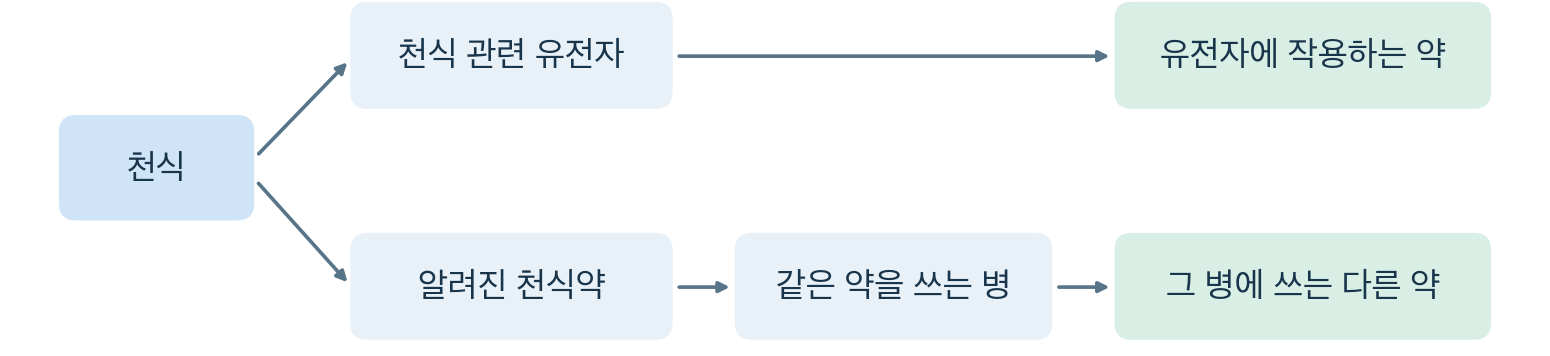

In [1]:
#@title PPR 흐름 그림 {display-mode: "form"}
import base64
from IPython.display import Image, display
_png = "..."
display(Image(data=base64.b64decode(_png)))


초록색 상자는 후보 약물이다. 화살표는 이동 경로의 예시다. 매번 65% 확률로 연결을 따라가고, 35% 확률로 천식으로 돌아간다. 이를 반복해 자주 들르는 후보 약을 앞에 놓는다.

추천 목록에서는 학습 데이터에 이미 들어 있는 해당 질병의 약을 뺐다.

| 단계 | 숫자 |
|---|---|
| 적응증 정제 | 금기와 겹친 339쌍 제외 후 57,835쌍 |
| 데이터 분할 | 학습 45,478쌍 · 검증 6,045쌍 · 테스트 6,312쌍 |
| 그래프 | 점 47,975개 · 연결 892,314개 |

이동 확률과 관계별 이동 비중은 검증 데이터에서 골랐다. 설정을 고정해 테스트한 뒤, 분할을 바꿔 5회 반복하고 유전자 연결 제거와 점수 기준(0.3·0.5) 비교도 했다.


### 이동 확률을 0.85에서 0.65로 바꾼 이유

초기에는 0.85로 그래프 전체를 검증했다. 이후 같은 검증 질병 1,661개에서 이동 확률 7개를 비교했다. 질병별 NDCG@100 평균이 0.85에서 0.2481, 0.65에서 0.2594였고, 비교한 값 중 0.65가 가장 높았다. 그래서 이동 확률을 0.65로 고정하고, 관계 비중을 따로 비교했다. 이동 확률을 고르는 데 테스트 결과는 쓰지 않았다.

| 이동 확률 | 검증 Recall@100 | 검증 NDCG@100 |
|---:|---:|---:|
| 0.50 | 0.5606 | 0.2579 |
| 0.65 | 0.5655 | 0.2594 |
| 0.75 | 0.5610 | 0.2566 |
| 0.80 | 0.5525 | 0.2532 |
| 0.85 | 0.5428 | 0.2481 |
| 0.90 | 0.5210 | 0.2385 |
| 0.95 | 0.4859 | 0.2154 |

출처는 `ppr_results/alpha_tuning/alpha_comparison.csv`와 `best_config.json`이다.

## 2. 결과표

아래 표와 그래프는 이전 실행에서 저장한 결과다.

- 최초 테스트 표는 `ppr_results/test_comparison/comparison_wide.csv`에서 가져왔다.
- 5회 평균 표와 그래프는 `ppr_results/repeated_splits/comparison_mean_std.csv`에서 가져왔다.
- 조절 PPR과 기본 PPR 차이의 신뢰구간은 `ppr_results/test_comparison/evaluation_summary.json`에 있다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
_avail = {f.name for f in font_manager.fontManager.ttflist}
for _name in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if _name in _avail:
        plt.rcParams['font.family'] = _name
        break
plt.rcParams['axes.unicode_minus'] = False

# 최초 테스트 (시드 42, 질병 1,928개, 정답 6,312쌍)
test = pd.DataFrame({
    '방법': ['인기 약물', '기본 PPR', '조절 PPR (약 95 : 유전자 5)'],
    'Recall@10': [0.0678, 0.2848, 0.2895],
    'NDCG@10': [0.0444, 0.2029, 0.2105],
    'Recall@100': [0.2447, 0.5807, 0.5871],
    'NDCG@100': [0.0852, 0.2728, 0.2799],
}).set_index('방법')
print('최초 테스트 (시드 42)')
display(test)

# 5회 반복 (시드 43–47), 평균 ± 표준편차
rep = pd.DataFrame({
    '방법': ['인기 약물', '기본 PPR', '조절 PPR (약 95 : 유전자 5)'],
    'Recall@10': ['0.0662 ± 0.0041', '0.2762 ± 0.0089', '0.2780 ± 0.0112'],
    'NDCG@10': ['0.0436 ± 0.0032', '0.1920 ± 0.0065', '0.1994 ± 0.0070'],
    'Recall@100': ['0.2416 ± 0.0060', '0.5745 ± 0.0052', '0.5755 ± 0.0064'],
    'NDCG@100': ['0.0833 ± 0.0023', '0.2626 ± 0.0057', '0.2698 ± 0.0058'],
}).set_index('방법')
print('5회 반복 평균 ± 표준편차')
display(rep)

최초 테스트 (시드 42)


,Recall@10,NDCG@10,Recall@100,NDCG@100
방법,,,,
인기 약물,0.0678,0.0444,0.2447,0.0852
기본 PPR,0.2848,0.2029,0.5807,0.2728
조절 PPR (약 95 : 유전자 5),0.2895,0.2105,0.5871,0.2799


5회 반복 평균 ± 표준편차


,Recall@10,NDCG@10,Recall@100,NDCG@100
방법,,,,
인기 약물,0.0662 ± 0.0041,0.0436 ± 0.0032,0.2416 ± 0.0060,0.0833 ± 0.0023
기본 PPR,0.2762 ± 0.0089,0.1920 ± 0.0065,0.5745 ± 0.0052,0.2626 ± 0.0057
조절 PPR (약 95 : 유전자 5),0.2780 ± 0.0112,0.1994 ± 0.0070,0.5755 ± 0.0064,0.2698 ± 0.0058


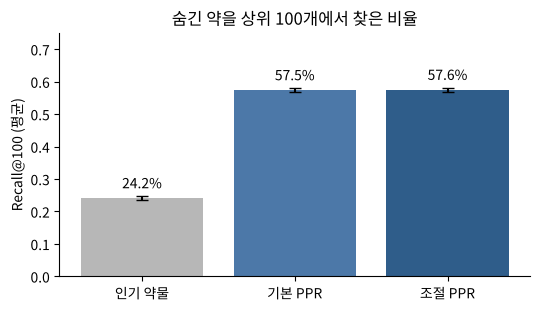

In [2]:
# Recall@100 그림 (5회 평균 ± 표준편차)
names = ['인기 약물', '기본 PPR', '조절 PPR']
mean = [0.2416, 0.5745, 0.5755]
sd = [0.0060, 0.0052, 0.0064]
fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.bar(names, mean, yerr=sd, capsize=4, color=['#b7b7b7', '#4c78a8', '#2f5d8a'])
for b, m in zip(bars, mean):
    ax.text(b.get_x() + b.get_width() / 2, m + 0.03, f'{m:.1%}', ha='center')
ax.set_ylim(0, 0.75); ax.set_ylabel('Recall@100 (평균)')
ax.set_title('숨긴 약을 상위 100개에서 찾은 비율')
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

두 PPR 모두 인기 약 추천보다 훨씬 잘 찾았다. 조절 PPR이 기본 PPR보다 조금 높긴 한데 차이가 작아서(최초 테스트 Recall@100 +0.64%p, 95% 구간 [-0.64, 2.02]%p) 확실히 낫다고 하기는 어렵다.

## 3. 유전자 연결은 얼마나 중요한가

- 유전자 제거 테스트 표는 `ppr_results/gene_ablation_test/comparison_wide.csv`, 신뢰구간은 같은 폴더의 `paired_bootstrap.csv`에서 가져왔다.
- 점수 기준 비교 표는 `ppr_results/score_threshold_validation/comparison_long.csv`와 `graph_info.csv`에서 가져왔다.

In [3]:
abl = pd.DataFrame({
    '구분': ['유전자 포함 (기본 PPR)', '유전자 제거 (질병–약물 연결만)'],
    'Recall@10': [0.2848, 0.2834],
    'Recall@100': [0.5807, 0.5670],
    'NDCG@100': [0.2728, 0.2751],
}).set_index('구분')
print('테스트 (시드 42, 이동 확률 0.65)')
display(abl)

thr = pd.DataFrame({
    '질병–유전자 점수 기준': ['0.3 이상 (사용)', '0.5 이상', '유전자 없음'],
    '질병–유전자 연결 수': [810225, 215943, 0],
    'Recall@100': [0.5655, 0.5803, 0.5569],
    'NDCG@100': [0.2594, 0.2690, 0.2635],
}).set_index('질병–유전자 점수 기준')
print('검증 (이동 확률 0.65, 기본 PPR)')
display(thr)

테스트 (시드 42, 이동 확률 0.65)


,Recall@10,Recall@100,NDCG@100
구분,,,
유전자 포함 (기본 PPR),0.2848,0.5807,0.2728
유전자 제거 (질병–약물 연결만),0.2834,0.5670,0.2751


검증 (이동 확률 0.65, 기본 PPR)


,질병–유전자 연결 수,Recall@100,NDCG@100
질병–유전자 점수 기준,,,
0.3 이상 (사용),810225,0.5655,0.2594
0.5 이상,215943,0.5803,0.2690
유전자 없음,0,0.5569,0.2635


- 유전자를 빼도 성능은 거의 같았다 (Recall@100 차이 1.4%p, 95% 구간 [-0.08, 2.98]%p). NDCG@100은 오히려 조금 높았다.
- 점수 기준을 0.5로 올리면 검증 Recall@100이 1.5%p 올랐지만 결론은 같았다. 팀에 공유한 데이터와 기존 PPR 실험에서 사용한 0.3 기준을 유지했다.


## 4. 한계

- 알려진 적응증을 다시 찾는 평가라서, 새 약의 치료 효과를 말해 주는 건 아니다.
- 학습용 적응증이 있는 질병만 평가했다. 학습용 적응증이 없는 질병에서 얼마나 되는지는 모른다.
- 질병–유전자 점수에 이미 알려진 약의 근거가 섞여 있을 수 있는데, 이건 가려내지 못했다.

## 5. 추가 실험

팀원 CBF 노트북의 분할 규칙을 재현해 시드 42~46으로 PPR을 다시 평가했다. 이 비교에는 금기 충돌 339쌍이 포함된 원본 적응증 58,174쌍을 썼다. 테스트마다 학습+검증으로 그래프를 만들고, 그 데이터에 등장한 약을 후보로 삼아 테스트 질병 1,662개를 평가했다. PPR 설정은 이동 확률 0.65, 조절 모델의 약물·유전자 비중 95:5로 고정했다.

| 방법 | Recall@10 (5회 평균 ± 표준편차) |
|---|---:|
| 인기 약물 기준선 | 0.0673 ± 0.0065 |
| 기본 CBF (팀원 PDF 수치) | 0.1826 ± 0.0017 |
| CBF + 인기 약물 보완 (팀원 PDF 수치) | 0.1901 ± 0.0024 |
| 기본 PPR | 0.2974 ± 0.0061 |
| 관계 비중 조절 PPR | 0.3075 ± 0.0055 |

CBF 두 행은 팀원 노트북에 저장된 결과다. PPR과 인기 약물 기준선은 팀원 조건을 재현해 계산했으며, 기준선은 팀원이 보고한 값과 일치했다. 


# PPR 구현 코드

그래프 생성부터 추천, 검증, 테스트, 반복 평가까지 순서대로 담았다. 앞부분 결과는 셀을 실행하지 않아도 볼 수 있다. 직접 계산할 때는 아래에서 입력 폴더를 지정하고 마지막 셀의 실행 스위치를 켠다.

## 입력 파일 준비
Python 3 노트북에서 NumPy와 SciPy를 설치한다. 원래 실험은 NumPy 2.4.6과 SciPy 1.18.0을 사용했다. 아래 `DATA_DIR`을 팀 CSV가 있는 폴더로 맞춘다. 실행 결과는 입력 데이터와 분리된 새 폴더에 저장된다.

코드 셀에는 기존 실험 스크립트의 함수가 들어 있다. 경로와 명령줄 인수는 노트북에서 전달하도록 바꿨다. 전체 실험을 다시 실행하는 스위치는 마지막 셀에 있다.

In [ ]:
from pathlib import Path
from shutil import copy2
from tempfile import mkdtemp

DATA_DIR = Path("data")
INPUT_FILES = (
    "indication_no_contraindication.csv", "indication_train.csv",
    "indication_validation.csv", "indication_test.csv",
    "disease_gene_t03.csv", "drug_gene.csv", "disease_names.csv", "drug_names.csv",
)

def prepare_run(data_dir, include_repeated=False):
    inputs = INPUT_FILES + (("indication.csv",) if include_repeated else ())
    missing = [name for name in inputs if not (data_dir / name).is_file()]
    if missing:
        raise FileNotFoundError(f"{data_dir.resolve()}에서 필요한 파일: {', '.join(missing)}")
    run_dir = Path(mkdtemp(prefix="ppr_run_", dir=Path.cwd()))
    for name in inputs:
        copy2(data_dir / name, run_dir / name)
    return run_dir

## 그래프 생성
학습용 적응증과 유전자 연결을 읽어 각 노드의 이동 확률을 계산한다.

In [ ]:
"""Build an unweighted, bidirectional graph and row-normalized PPR transition matrix."""
import argparse
import csv
import hashlib
import json
from collections import Counter
from pathlib import Path

import numpy as np
import scipy
from scipy import sparse
from scipy.sparse.csgraph import connected_components


def read_pairs(path, left, right):
    pairs = set()
    count = 0
    with path.open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        if not {left, right}.issubset(reader.fieldnames or []):
            raise ValueError(f"Missing required columns: {path}")
        for row in reader:
            a, b = row[left].strip(), row[right].strip()
            if not a or not b:
                raise ValueError(f"Empty endpoint: {path}, row {reader.line_num}")
            pairs.add((a, b))
            count += 1
    return pairs, count


def build_ppr_graph(root, argv=()):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data-dir", type=Path, default=Path(root).resolve())
    parser.add_argument("--output-dir", type=Path)
    args = parser.parse_args(argv)
    root = args.data_dir.resolve()
    output = args.output_dir or root / "ppr_graph"
    specs = [
        ("indication_train.csv", "disease_id", "drug_id", "disease", "drug", "indication"),
        ("disease_gene_t03.csv", "disease_id", "gene_id", "disease", "gene", "disease_gene"),
        ("drug_gene.csv", "drug_id", "gene_id", "drug", "gene", "drug_gene"),
    ]
    relations, nodes, sources = [], set(), {}
    for filename, left, right, lt, rt, relation in specs:
        path = root / filename
        pairs, row_count = read_pairs(path, left, right)
        relations.append((relation, lt, rt, sorted(pairs)))
        nodes.update((lt, a) for a, _ in pairs)
        nodes.update((rt, b) for _, b in pairs)
        sources[filename] = {
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
            "rows": row_count, "unique_pairs": len(pairs),
            "duplicate_pairs_removed": row_count - len(pairs),
        }

    # Held-out files are used only for audits, never to construct edges or nodes.
    train = set(relations[0][3])
    held = {}
    audit = {}
    for split in ("validation", "test"):
        path = root / f"indication_{split}.csv"
        if path.exists():
            pairs, _ = read_pairs(path, "disease_id", "drug_id")
            if pairs & train:
                raise ValueError(f"Training overlap in {split}")
            held[split] = pairs
            audit[split] = {"pairs": len(pairs), "overlap_with_training": 0}
    if held.get("validation", set()) & held.get("test", set()):
        raise ValueError("Validation/test overlap")

    ordered_nodes = sorted(nodes)
    index = {node: i for i, node in enumerate(ordered_nodes)}
    edge_count = sum(len(pairs) for _, _, _, pairs in relations)
    rows = np.empty(edge_count, dtype=np.int32)
    cols = np.empty(edge_count, dtype=np.int32)
    offset = 0
    for _, lt, rt, pairs in relations:
        for a, b in pairs:
            rows[offset], cols[offset] = index[lt, a], index[rt, b]
            offset += 1
    n = len(ordered_nodes)
    adjacency = sparse.coo_matrix(
        (np.ones(edge_count * 2, dtype=np.float64),
         (np.concatenate([rows, cols]), np.concatenate([cols, rows]))), shape=(n, n)
    ).tocsr()
    adjacency.sum_duplicates()
    adjacency.data.fill(1.0)
    adjacency.sort_indices()
    degree = np.asarray(adjacency.sum(axis=1)).ravel()
    inv_degree = np.divide(1.0, degree, out=np.zeros_like(degree), where=degree != 0)
    transition = (sparse.diags(inv_degree) @ adjacency).tocsr()
    transition.sort_indices()
    row_sums = np.asarray(transition.sum(axis=1)).ravel()
    assert adjacency.nnz == edge_count * 2
    assert (adjacency != adjacency.T).nnz == 0
    assert not adjacency.diagonal().any()
    assert np.allclose(row_sums[degree > 0], 1.0)

    # Check actual matrix entries, in both directions, for every held-out pair.
    for split, pairs in held.items():
        found = 0
        for disease, drug in pairs:
            a, b = index.get(("disease", disease)), index.get(("drug", drug))
            if a is not None and b is not None:
                found += int(adjacency[a, b] != 0 or adjacency[b, a] != 0)
        assert found == 0
        audit[split]["direct_edges_in_graph"] = found

    component_count, labels = connected_components(adjacency, directed=False)
    summary = {
        "nodes": n, "nodes_by_type": dict(Counter(t for t, _ in ordered_nodes)),
        "unique_undirected_edges": edge_count, "directed_matrix_entries": adjacency.nnz,
        "edges_by_relation": {relation: len(pairs) for relation, _, _, pairs in relations},
        "connected_components": int(component_count),
        "largest_component_nodes": int(np.bincount(labels).max()),
        "isolated_nodes": int(np.sum(degree == 0)),
        "design": {
            "direction": "bidirectional", "edge_weight": 1.0,
            "disease_gene_score": "thresholded input; score not used as weight",
            "drug_gene_action": "connectivity only; action not used as sign or weight",
            "transition": "P[i,j] = A[i,j] / degree(i); each nonempty row sums to 1",
            "ppr_equation": "r_next = alpha * P.T @ r + (1-alpha) * seed",
            "node_universe": "endpoints from three training graph inputs only",
        },
        "held_out_audit": audit, "sources": sources,
        "environment": {"numpy": np.__version__, "scipy": scipy.__version__},
    }
    output.mkdir(parents=True, exist_ok=True)
    sparse.save_npz(output / "adjacency.npz", adjacency)
    sparse.save_npz(output / "transition.npz", transition)
    with (output / "nodes.csv").open("w", encoding="utf-8", newline="") as stream:
        writer = csv.writer(stream)
        writer.writerow(["node_index", "node_type", "node_id", "degree", "component_id"])
        writer.writerows((i, t, node_id, int(degree[i]), int(labels[i]))
                         for i, (t, node_id) in enumerate(ordered_nodes))
    (output / "graph_summary.json").write_text(
        json.dumps(summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    # Verify persisted artifacts, not only the in-memory matrices.
    for name, expected in [("adjacency", adjacency), ("transition", transition)]:
        loaded = sparse.load_npz(output / f"{name}.npz")
        assert loaded.shape == expected.shape and (loaded != expected).nnz == 0
    for filename, info in sources.items():
        assert hashlib.sha256((root / filename).read_bytes()).hexdigest() == info["sha256"]
    print(json.dumps(summary, ensure_ascii=False, indent=2))

## PPR 점수와 약물 추천

질병에서 시작해 매 단계 이동 확률만큼 연결을 따라가고, 나머지 확률로 시작 질병에 돌아온다. 점수가 수렴하면 그 질병의 학습용 약을 빼고 후보를 점수순으로 정렬한다. 마지막 절에서 천식 추천으로 확인할 수 있다.

In [ ]:
"""Rank candidate drugs using single-disease personalized PageRank."""
import argparse
import csv
import hashlib
import json
import time
from pathlib import Path

import numpy as np
from scipy import sparse


def read_recommendation_csv(path):
    with path.open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


def recommend_ppr(root, argv=()):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data-dir", type=Path, default=Path(root).resolve())
    parser.add_argument("--disease-id", default="MONDO_0004979")
    parser.add_argument("--alpha", type=float, default=0.65,
                        help="Probability of following an edge (0.65 = value selected on validation)")
    parser.add_argument("--tol", type=float, default=1e-10, help="Absolute L1 iteration tolerance")
    parser.add_argument("--max-iter", type=int, default=1000)
    parser.add_argument("--top-k", type=int, default=10)
    args = parser.parse_args(argv)
    if not 0 < args.alpha < 1 or args.tol <= 0 or args.top_k < 1 or args.max_iter < 1:
        parser.error("Invalid alpha, tolerance, top-k or max-iter")
    root = args.data_dir.resolve()
    graph = root / "ppr_graph"
    metadata = json.loads((graph / "graph_summary.json").read_text(encoding="utf-8"))
    for filename, info in metadata["sources"].items():
        if hashlib.sha256((root / filename).read_bytes()).hexdigest() != info["sha256"]:
            raise ValueError(f"Input changed since graph creation: {filename}")
    nodes = read_recommendation_csv(graph / "nodes.csv")
    assert [int(r["node_index"]) for r in nodes] == list(range(len(nodes)))
    index = {(r["node_type"], r["node_id"]): int(r["node_index"]) for r in nodes}
    seed_index = index.get(("disease", args.disease_id))
    if seed_index is None:
        raise ValueError("Disease not found in graph")
    transition = sparse.load_npz(graph / "transition.npz")
    assert transition.shape == (len(nodes), len(nodes))
    row_sums = np.asarray(transition.sum(axis=1)).ravel()
    dangling = row_sums == 0
    assert np.allclose(row_sums[~dangling], 1.0)
    assert np.all(transition.data >= 0)
    seed = np.zeros(len(nodes), dtype=float)
    seed[seed_index] = 1.0
    transposed = transition.T.tocsr()

    def step(scores):
        return args.alpha * (transposed @ scores + scores[dangling].sum() * seed) + (1 - args.alpha) * seed

    scores = seed.copy()
    start = time.perf_counter()
    for iteration in range(1, args.max_iter + 1):
        updated = step(scores)
        delta = float(np.linalg.norm(updated - scores, ord=1))
        scores = updated
        if delta < args.tol:
            break
    else:
        raise RuntimeError("PPR did not converge; no ranking saved")
    seconds = time.perf_counter() - start
    residual = float(np.linalg.norm(step(scores) - scores, ord=1))
    assert residual < args.tol
    assert np.isclose(scores.sum(), 1.0) and np.all(scores >= 0)

    candidates = {r["drug_id"] for r in read_recommendation_csv(root / "indication_no_contraindication.csv")}
    known = {r["drug_id"] for r in read_recommendation_csv(root / "indication_train.csv")
             if r["disease_id"] == args.disease_id}
    drug_names = {r["drug_id"]: r["name"] or r["drug_id"] for r in read_recommendation_csv(root / "drug_names.csv")}
    disease_names = {r["disease_id"]: r["name"] for r in read_recommendation_csv(root / "disease_names.csv")}
    eligible = candidates - known
    drug_scores = {
        drug: float(scores[index["drug", drug]]) if ("drug", drug) in index else 0.0
        for drug in eligible
    }
    # Stable deterministic tie breaking, including candidates absent from graph.
    ranked = sorted(eligible, key=lambda drug: (-drug_scores[drug], drug))
    top = [{"rank": rank, "drug_id": drug, "drug_name": drug_names.get(drug, drug),
            "ppr_score": drug_scores[drug]}
           for rank, drug in enumerate(ranked[:args.top_k], 1)]
    assert not {r["drug_id"] for r in top} & known
    output = root / "ppr_results"
    output.mkdir(exist_ok=True)
    prefix = args.disease_id
    with (output / f"{prefix}_top{args.top_k}.csv").open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=["rank", "drug_id", "drug_name", "ppr_score"])
        writer.writeheader()
        writer.writerows(top)
    summary = {
        "disease_id": args.disease_id, "disease_name": disease_names.get(args.disease_id),
        "alpha": args.alpha, "restart_probability": 1 - args.alpha,
        "l1_tolerance": args.tol, "iterations": iteration,
        "last_l1_delta": delta, "fixed_point_l1_residual": residual,
        "score_sum_all_nodes": float(scores.sum()), "ppr_iteration_seconds": seconds,
        "candidate_drugs_total": len(candidates), "training_drugs_excluded": len(candidates & known),
        "eligible_candidates": len(eligible),
        "eligible_candidates_absent_from_graph": sum(("drug", d) not in index for d in eligible),
        "positive_score_candidates": sum(v > 0 for v in drug_scores.values()),
        "tie_breaking": "drug_id ascending", "absent_candidate_score": 0,
        "score_interpretation": "PPR mass over all graph nodes; not treatment probability",
        "held_out_labels_used_for_scoring": False,
        "top_drugs": top,
    }
    (output / f"{prefix}_summary.json").write_text(
        json.dumps(summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    assert len(read_recommendation_csv(output / f"{prefix}_top{args.top_k}.csv")) == len(top)
    print(json.dumps(summary, ensure_ascii=False, indent=2))

## 평가 지표
이 함수는 테스트 비교 등에서 질병별 상위 K개 추천을 평가하는 데 사용된다.

In [ ]:
import math

def metrics(ranking, truth, k):
    if not truth:
        raise ValueError("No validation positives")
    hits = [int(drug in truth) for drug in ranking[:k]]
    dcg = sum(hit / math.log2(rank + 1) for rank, hit in enumerate(hits, 1))
    ideal = sum(1 / math.log2(rank + 1) for rank in range(1, min(k, len(truth)) + 1))
    return {"K": k, "hits": sum(hits), "validation_positives": len(truth),
            "recall": sum(hits) / len(truth), "ndcg": dcg / ideal}

## 검증 평가
초기 이동 확률 0.85에서 검증 점수를 계산한다. 유전자 없는 그래프도 같은 함수로 평가할 수 있다.

In [ ]:
"""Evaluate fixed-alpha PPR for every disease with validation positives."""
import argparse
import csv
import hashlib
import json
import math
import time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import scipy
from scipy import sparse


def read_csv(path):
    with path.open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


def write_csv(path, rows):
    with path.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def evaluate_all_validation(root, argv=()):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data-dir", type=Path, default=Path(root).resolve())
    parser.add_argument("--workers", type=int, default=4)
    parser.add_argument("--graph-variant", choices=["full", "indication-only"], default="full")
    args = parser.parse_args(argv)
    if args.workers < 1:
        parser.error("workers must be positive")
    root = args.data_dir.resolve()
    output = root / "ppr_results" / ("all_validation" if args.graph_variant == "full" else "indication_only_validation")
    output.mkdir(parents=True, exist_ok=True)
    graph = root / "ppr_graph"
    metadata = json.loads((graph / "graph_summary.json").read_text(encoding="utf-8"))
    for filename, info in metadata["sources"].items():
        if hashlib.sha256((root / filename).read_bytes()).hexdigest() != info["sha256"]:
            raise ValueError(f"Graph inputs changed: {filename}")
    started = time.perf_counter()
    train, truth = defaultdict(set), defaultdict(set)
    for row in read_csv(root / "indication_train.csv"):
        train[row["disease_id"]].add(row["drug_id"])
    for row in read_csv(root / "indication_validation.csv"):
        truth[row["disease_id"]].add(row["drug_id"])
    candidates = sorted({r["drug_id"] for r in read_csv(root / "indication_no_contraindication.csv")})
    candidate_set = set(candidates)
    nodes = read_csv(graph / "nodes.csv")
    assert [int(r["node_index"]) for r in nodes] == list(range(len(nodes)))
    index = {(r["node_type"], r["node_id"]): int(r["node_index"]) for r in nodes}
    drug_indices = np.array([index.get(("drug", d), -1) for d in candidates])
    present = drug_indices >= 0
    candidate_position = {d: i for i, d in enumerate(candidates)}
    names = {r["disease_id"]: r["name"] for r in read_csv(root / "disease_names.csv")}
    if args.graph_variant == "full":
        transition = sparse.load_npz(graph / "transition.npz")
    else:
        # Preserve the node index and candidate universe; remove BOTH gene relation types.
        # Former gene nodes are isolated and unreachable from every disease seed.
        edge_rows, edge_cols = [], []
        for disease, drugs in train.items():
            for drug in sorted(drugs):
                a, b = index["disease", disease], index["drug", drug]
                edge_rows.extend([a, b])
                edge_cols.extend([b, a])
        adjacency = sparse.coo_matrix(
            (np.ones(len(edge_rows)), (edge_rows, edge_cols)),
            shape=(len(nodes), len(nodes)),
        ).tocsr()
        assert adjacency.nnz == 2 * sum(map(len, train.values()))
        assert (adjacency != adjacency.T).nnz == 0
        degrees = np.asarray(adjacency.sum(axis=1)).ravel()
        for node in nodes:
            if node["node_type"] == "gene":
                assert degrees[int(node["node_index"])] == 0
        for disease, positives in truth.items():
            for drug in positives:
                d, t = index.get(("disease", disease)), index.get(("drug", drug))
                if d is not None and t is not None:
                    assert adjacency[d, t] == 0 and adjacency[t, d] == 0
        inverse = np.divide(1.0, degrees, out=np.zeros_like(degrees), where=degrees != 0)
        transition = (sparse.diags(inverse) @ adjacency).tocsr()
        sparse.save_npz(output / "transition_indication_only.npz", transition)
    assert transition.shape == (len(nodes), len(nodes))
    row_sums = np.asarray(transition.sum(axis=1)).ravel()
    dangling = row_sums == 0
    assert np.allclose(row_sums[~dangling], 1) and np.all(transition.data >= 0)
    transposed = transition.T.tocsr()
    alpha, tolerance, max_iter, ks = 0.85, 1e-10, 1000, [10, 20, 50, 100]
    discounts = 1 / np.log2(np.arange(1, 101) + 1)
    assert math.isclose(float(discounts[1]), 1 / math.log2(3))
    for disease, positives in truth.items():
        assert positives and not positives & train[disease]
        assert positives <= candidate_set
        assert ("disease", disease) in index

    def evaluate(disease):
        start = time.perf_counter()
        seed_index = index["disease", disease]
        scores = np.zeros(len(nodes))
        scores[seed_index] = 1

        def step(vector):
            updated = alpha * (transposed @ vector)
            updated[seed_index] += (1 - alpha) + alpha * vector[dangling].sum()
            return updated

        for iteration in range(1, max_iter + 1):
            updated = step(scores)
            delta = float(np.abs(updated - scores).sum())
            scores = updated
            if delta < tolerance:
                break
        else:
            raise RuntimeError(f"Did not converge: {disease}")
        residual = float(np.abs(step(scores) - scores).sum())
        assert residual < tolerance and np.isclose(scores.sum(), 1) and np.all(scores >= 0)
        values = np.zeros(len(candidates))
        values[present] = scores[drug_indices[present]]
        known = [candidate_position[d] for d in train[disease] if d in candidate_position]
        values[known] = -np.inf
        # Candidates are ID-sorted; stable sorting gives the same tie rule as recommend_ppr.py.
        order = np.argsort(-values, kind="stable")
        assert len(candidates) - len(known) >= max(ks)
        ranking = [candidates[i] for i in order[:max(ks)]]
        assert not set(ranking) & train[disease]
        positives = truth[disease]
        relevance = np.array([d in positives for d in ranking], dtype=int)
        row = {
            "disease_id": disease, "disease_name": names.get(disease, disease),
            "training_positives": len(train[disease]), "validation_positives": len(positives),
            "validation_positives_absent_from_graph": sum(("drug", d) not in index for d in positives),
            "eligible_candidates": len(candidates) - len(known),
            "positive_score_candidates": int(np.sum(values > 0)),
            "iterations": iteration, "fixed_point_l1_residual": residual,
        }
        for k in ks:
            hits = int(relevance[:k].sum())
            ideal = float(discounts[:min(k, len(positives))].sum())
            row[f"hits_at_{k}"] = hits
            row[f"recall_at_{k}"] = hits / len(positives)
            row[f"ndcg_at_{k}"] = float(np.dot(relevance[:k], discounts[:k])) / ideal
        row["compute_seconds"] = time.perf_counter() - start
        return row

    diseases = sorted(truth)
    results = []
    print(f"Evaluating {len(diseases)} diseases with {args.workers} workers", flush=True)
    with ThreadPoolExecutor(max_workers=args.workers) as executor:
        for row in executor.map(evaluate, diseases):
            results.append(row)
            if len(results) % 100 == 0 or len(results) == len(diseases):
                print(f"Completed {len(results)}/{len(diseases)}; elapsed {time.perf_counter()-started:.1f}s", flush=True)
    # Independent consistency check against the earlier single-disease run.
    asthma_path = root / "ppr_results" / "MONDO_0004979_validation_summary.json"
    if args.graph_variant == "full" and asthma_path.exists() and "MONDO_0004979" in truth:
        previous = json.loads(asthma_path.read_text(encoding="utf-8"))
        asthma = next(r for r in results if r["disease_id"] == "MONDO_0004979")
        for metric in previous["metrics"]:
            k = metric["K"]
            assert asthma[f"hits_at_{k}"] == metric["hits"]
            assert math.isclose(asthma[f"recall_at_{k}"], metric["recall"], abs_tol=1e-12)
            assert math.isclose(asthma[f"ndcg_at_{k}"], metric["ndcg"], abs_tol=1e-12)
    total_positives = sum(r["validation_positives"] for r in results)
    aggregated = [{
        "K": k, "evaluated_diseases": len(results), "validation_positives": total_positives,
        "total_hits": sum(r[f"hits_at_{k}"] for r in results),
        "macro_recall": float(np.mean([r[f"recall_at_{k}"] for r in results])),
        "macro_ndcg": float(np.mean([r[f"ndcg_at_{k}"] for r in results])),
        "micro_recall": sum(r[f"hits_at_{k}"] for r in results) / total_positives,
        "diseases_with_at_least_one_hit": sum(r[f"hits_at_{k}"] > 0 for r in results),
    } for k in ks]
    validation_absent = sum(r["validation_positives_absent_from_graph"] for r in results)
    summary = {
        "split": "validation", "test_labels_read": False,
        "graph_variant": args.graph_variant,
        "graph_directed_entries": int(transition.nnz),
        "isolated_nodes": int(dangling.sum()),
        "nodes_retained_for_index_compatibility": len(nodes),
        "validation_positives_without_graph_edges": sum(
            int(("drug", drug) not in index or dangling[index["drug", drug]])
            for drugs in truth.values() for drug in drugs),
        "evaluated_diseases": len(results), "training_diseases": len(train),
        "diseases_without_validation_excluded": len(set(train) - set(truth)),
        "validation_positives": total_positives,
        "candidate_drugs": len(candidates),
        "validation_positives_absent_from_graph": validation_absent,
        "alpha": alpha, "restart_probability": 1-alpha, "absolute_l1_tolerance": tolerance,
        "workers": args.workers, "total_wall_seconds": time.perf_counter() - started,
        "max_iterations_observed": max(r["iterations"] for r in results),
        "max_fixed_point_l1_residual": max(r["fixed_point_l1_residual"] for r in results),
        "policy": {
            "main_averaging": "macro: each disease has equal weight",
            "micro_recall": "total hits / total validation positives",
            "relevance": "binary; all validation positives retained in denominator",
            "ndcg": "DCG=sum(rel_i/log2(i+1)); IDCG uses min(K, number of validation positives)",
            "candidate_universe": "drugs occurring in cleaned full indications, fixed before evaluation",
            "mask": "exclude only query disease's training drugs",
            "absent_nodes": "score zero, retained as candidates and validation positives",
            "tie_breaking": "drug_id ascending", "unreachable_nodes": "score zero",
            "timing": "per-disease time includes PPR, ranking, metrics and thread contention; wall time is overall duration",
        },
        "environment": {"numpy": np.__version__, "scipy": scipy.__version__},
        "input_sha256": {name: hashlib.sha256((root / name).read_bytes()).hexdigest()
                         for name in ["indication_train.csv", "indication_validation.csv", "indication_no_contraindication.csv"]},
        "metrics": aggregated,
    }
    assert total_positives == 6045
    assert len(results) == len(diseases)
    write_csv(output / "per_disease_metrics.csv", results)
    write_csv(output / "aggregate_metrics.csv", aggregated)
    (output / "evaluation_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    assert len(read_csv(output / "per_disease_metrics.csv")) == len(results)
    print(json.dumps(summary, ensure_ascii=False, indent=2), flush=True)

### 검증 데이터의 인기 약물 기준선
학습용 질병 수로 약물 인기를 계산해 같은 검증 정답을 평가한다.

In [ ]:
"""Training-only popularity baseline, evaluated on the same validation set as PPR."""
import csv
import hashlib
import json
import math
import time
from collections import Counter, defaultdict
from pathlib import Path



def evaluate_popularity_validation(root):
    root = Path(root).resolve()
    ppr_dir = root / "ppr_results" / "all_validation"
    ppr_summary = json.loads((ppr_dir / "evaluation_summary.json").read_text(encoding="utf-8"))
    hashes = {}
    for name, expected in ppr_summary["input_sha256"].items():
        hashes[name] = hashlib.sha256((root / name).read_bytes()).hexdigest()
        if hashes[name] != expected:
            raise ValueError(f"Input differs from PPR evaluation: {name}")
    ppr_rows = {r["disease_id"]: r for r in read_csv(ppr_dir / "per_disease_metrics.csv")}
    started = time.perf_counter()
    training = defaultdict(set)
    for row in read_csv(root / "indication_train.csv"):
        training[row["disease_id"]].add(row["drug_id"])
    truth = defaultdict(set)
    for row in read_csv(root / "indication_validation.csv"):
        truth[row["disease_id"]].add(row["drug_id"])
    assert set(truth) == set(ppr_rows)
    candidates = {r["drug_id"] for r in read_csv(root / "indication_no_contraindication.csv")}
    assert len(candidates) == ppr_summary["candidate_drugs"]
    # One count per unique disease-drug training pair, never using validation counts.
    frequency = Counter(drug for drugs in training.values() for drug in drugs)
    assert sum(frequency.values()) == sum(len(v) for v in training.values())
    ordered = sorted(candidates, key=lambda drug: (-frequency[drug], drug))
    ks = [10, 20, 50, 100]
    names = {r["disease_id"]: r["name"] for r in read_csv(root / "disease_names.csv")}
    results, paired = [], []
    for disease in sorted(truth):
        start = time.perf_counter()
        known, positives = training[disease], truth[disease]
        assert not known & positives and positives <= candidates
        ranking = []
        for drug in ordered:
            if drug not in known:
                ranking.append(drug)
                if len(ranking) == max(ks):
                    break
        assert len(set(ranking)) == 100 and not set(ranking) & known
        previous = ppr_rows[disease]
        assert len(positives) == int(previous["validation_positives"])
        assert len(candidates - known) == int(previous["eligible_candidates"])
        row = {"disease_id": disease, "disease_name": names.get(disease, disease),
               "training_positives": len(known), "validation_positives": len(positives),
               "eligible_candidates": len(candidates - known)}
        delta_row = {"disease_id": disease, "disease_name": names.get(disease, disease)}
        for k in ks:
            value = metrics(ranking, positives, k)
            row[f"hits_at_{k}"] = value["hits"]
            row[f"recall_at_{k}"] = value["recall"]
            row[f"ndcg_at_{k}"] = value["ndcg"]
            delta_row[f"recall_delta_at_{k}"] = float(previous[f"recall_at_{k}"]) - value["recall"]
            delta_row[f"ndcg_delta_at_{k}"] = float(previous[f"ndcg_at_{k}"]) - value["ndcg"]
        row["compute_seconds"] = time.perf_counter() - start
        results.append(row)
        paired.append(delta_row)
    total_positives = sum(r["validation_positives"] for r in results)
    assert total_positives == ppr_summary["validation_positives"]
    aggregated, comparison = [], []
    for k in ks:
        hits = sum(r[f"hits_at_{k}"] for r in results)
        recall = math.fsum(r[f"recall_at_{k}"] for r in results) / len(results)
        ndcg = math.fsum(r[f"ndcg_at_{k}"] for r in results) / len(results)
        aggregated.append({"K": k, "evaluated_diseases": len(results), "validation_positives": total_positives,
                           "total_hits": hits, "macro_recall": recall, "macro_ndcg": ndcg,
                           "micro_recall": hits / total_positives,
                           "diseases_with_at_least_one_hit": sum(r[f"hits_at_{k}"] > 0 for r in results)})
        prior = next(r for r in ppr_summary["metrics"] if r["K"] == k)
        for metric in ["recall", "ndcg"]:
            assert math.isclose(math.fsum(float(r[f"{metric}_at_{k}"]) for r in ppr_rows.values()) / len(results), prior[f"macro_{metric}"], abs_tol=1e-12)
        deltas = [r[f"recall_delta_at_{k}"] for r in paired]
        comparison.append({
            "K": k, "popularity_macro_recall": recall, "ppr_macro_recall": prior["macro_recall"],
            "recall_difference": prior["macro_recall"] - recall,
            "recall_relative_lift_percent": (prior["macro_recall"] / recall - 1) * 100 if recall else None,
            "popularity_macro_ndcg": ndcg, "ppr_macro_ndcg": prior["macro_ndcg"],
            "ndcg_difference": prior["macro_ndcg"] - ndcg,
            "ndcg_relative_lift_percent": (prior["macro_ndcg"] / ndcg - 1) * 100 if ndcg else None,
            "popularity_total_hits": hits, "ppr_total_hits": prior["total_hits"],
            "popularity_micro_recall": hits / total_positives, "ppr_micro_recall": prior["micro_recall"],
            "ppr_recall_wins": sum(d > 1e-12 for d in deltas),
            "ppr_recall_ties": sum(abs(d) <= 1e-12 for d in deltas),
            "ppr_recall_losses": sum(d < -1e-12 for d in deltas),
        })
    output = root / "ppr_results" / "popularity_validation"
    output.mkdir(parents=True, exist_ok=True)
    write_csv(output / "per_disease_metrics.csv", results)
    write_csv(output / "aggregate_metrics.csv", aggregated)
    write_csv(output / "ppr_comparison.csv", comparison)
    write_csv(output / "per_disease_comparison.csv", paired)
    write_csv(output / "training_drug_popularity.csv", [
        {"rank": i, "drug_id": drug, "training_disease_count": frequency[drug]}
        for i, drug in enumerate(ordered, 1)])
    summary = {
        "split": "validation", "test_labels_read": False,
        "scoring": "number of unique training diseases linked to the drug",
        "candidate_drugs": len(candidates), "evaluated_diseases": len(results),
        "validation_positives": total_positives,
        "diseases_without_validation_excluded": ppr_summary["diseases_without_validation_excluded"],
        "policy": "Same candidates and validation labels as PPR; exclude query disease's training drugs; score unseen drugs zero; ties by drug_id; binary NDCG; macro means give diseases equal weight",
        "input_sha256": hashes, "metrics": aggregated, "comparison": comparison,
        "total_wall_seconds": time.perf_counter() - started,
        "timing_note": "Popularity timing excludes loading PPR and input hash checks; PPR used 4 workers, popularity uses 1. These are separate runs and not a controlled speed benchmark.",
        "interpretation_limit": "Comparison tests the complete PPR method against popularity; it does not isolate the contribution of gene relations. Validation results are not final test performance.",
    }
    (output / "evaluation_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    assert len(read_csv(output / "per_disease_metrics.csv")) == len(results)
    print(json.dumps(summary, ensure_ascii=False, indent=2))

### 검증에서 이동 확률 선택
검증 NDCG@100을 기준으로 이동 확률을 비교한다.

In [ ]:
"""Select PPR alpha by validation macro NDCG@100; never read test labels."""
import argparse
import hashlib
import json
import math
import time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
from scipy import sparse



def tune_ppr_alpha(root, argv=()):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--workers", type=int, default=4)
    parser.add_argument("--batch-size", type=int, default=32)
    args = parser.parse_args(argv)
    root = Path(root).resolve()
    output = root / "ppr_results" / "alpha_tuning"
    output.mkdir(parents=True, exist_ok=True)
    baseline_dir = root / "ppr_results" / "all_validation"
    baseline = json.loads((baseline_dir / "evaluation_summary.json").read_text(encoding="utf-8"))
    for filename, digest in baseline["input_sha256"].items():
        assert hashlib.sha256((root / filename).read_bytes()).hexdigest() == digest, filename
    graph_dir = root / "ppr_graph"
    graph_summary = json.loads((graph_dir / "graph_summary.json").read_text(encoding="utf-8"))
    for filename, info in graph_summary["sources"].items():
        assert hashlib.sha256((root / filename).read_bytes()).hexdigest() == info["sha256"], filename
    train, truth = defaultdict(set), defaultdict(set)
    for row in read_csv(root / "indication_train.csv"):
        train[row["disease_id"]].add(row["drug_id"])
    for row in read_csv(root / "indication_validation.csv"):
        truth[row["disease_id"]].add(row["drug_id"])
    diseases = sorted(truth)
    assert len(diseases) == baseline["evaluated_diseases"]
    candidates = sorted({r["drug_id"] for r in read_csv(root / "indication_no_contraindication.csv")})
    positions = {d: i for i, d in enumerate(candidates)}
    nodes = read_csv(graph_dir / "nodes.csv")
    index = {(r["node_type"], r["node_id"]): int(r["node_index"]) for r in nodes}
    names = {r["disease_id"]: r["name"] for r in read_csv(root / "disease_names.csv")}
    n = len(nodes)
    drug_indices = np.array([index.get(("drug", d), -1) for d in candidates])
    present = drug_indices >= 0
    transition = sparse.load_npz(graph_dir / "transition.npz")
    assert transition.shape == (n, n)
    row_sums = np.asarray(transition.sum(axis=1)).ravel()
    assert np.allclose(row_sums, 1)  # This fixed graph has no dangling nodes.
    transposed = transition.T.tocsr()
    tolerance, max_iter, ks = 1e-10, 5000, [10, 20, 50, 100]
    for d in diseases:
        assert truth[d] <= set(candidates) and not truth[d] & train[d]

    def solve_batch(batch, alpha):
        seeds = np.array([index["disease", d] for d in batch])
        active = np.arange(len(batch))
        scores = np.zeros((n, len(batch)))
        scores[seeds, active] = 1
        finished = np.zeros_like(scores)
        iterations = np.zeros(len(batch), dtype=int)
        for iteration in range(1, max_iter + 1):
            updated = alpha * (transposed @ scores)
            updated[seeds[active], np.arange(len(active))] += 1 - alpha
            delta = np.abs(updated - scores).sum(axis=0)
            done = delta < tolerance
            if done.any():
                finished[:, active[done]] = updated[:, done]
                iterations[active[done]] = iteration
            active = active[~done]
            if len(active) == 0:
                break
            scores = updated[:, ~done]
        else:
            raise RuntimeError(f"Nonconverged batch for alpha={alpha}")
        residual_values = alpha * (transposed @ finished)
        residual_values[seeds, np.arange(len(batch))] += 1 - alpha
        residual = np.abs(residual_values - finished).sum(axis=0)
        assert np.all(residual < tolerance)
        assert np.allclose(finished.sum(axis=0), 1) and np.all(finished >= 0)
        results = []
        for j, d in enumerate(batch):
            values = np.zeros(len(candidates))
            values[present] = finished[drug_indices[present], j]
            known = [positions[drug] for drug in train[d] if drug in positions]
            values[known] = -np.inf
            order = np.argsort(-values, kind="stable")[:100]
            ranking = [candidates[i] for i in order]
            assert len(ranking) == 100 and not set(ranking) & train[d]
            row = {"disease_id": d, "disease_name": names.get(d, d),
                   "validation_positives": len(truth[d]), "iterations": int(iterations[j]),
                   "fixed_point_l1_residual": float(residual[j])}
            for k in ks:
                value = metrics(ranking, truth[d], k)
                for key in ["hits", "recall", "ndcg"]:
                    row[f"{key}_at_{k}"] = value[key]
            results.append(row)
        return results

    previous = {r["disease_id"]: r for r in read_csv(baseline_dir / "per_disease_metrics.csv")}
    # Verify batching reproduces the single-seed evaluator before sweeping settings.
    check_diseases = list(dict.fromkeys(diseases[:args.batch_size] + ["MONDO_0004979"]))
    for row in solve_batch(check_diseases, 0.85):
        for k in ks:
            assert row[f"hits_at_{k}"] == int(previous[row["disease_id"]][f"hits_at_{k}"])
            for metric in ["recall", "ndcg"]:
                assert math.isclose(row[f"{metric}_at_{k}"], float(previous[row["disease_id"]][f"{metric}_at_{k}"]), abs_tol=1e-12)
    print("Verified batch implementation against prior alpha=0.85 results", flush=True)
    batches = [diseases[i:i+args.batch_size] for i in range(0, len(diseases), args.batch_size)]
    records = []
    started = time.perf_counter()

    def run(alpha):
        label = f"alpha_{alpha:.3f}".replace(".", "p")
        directory = output / label
        directory.mkdir(exist_ok=True)
        begin = time.perf_counter()
        if alpha == 0.85:
            results = [previous[d] for d in diseases]
            aggregates = baseline["metrics"]
            source = "reused unchanged prior full-graph validation evaluation"
        else:
            results = []
            with ThreadPoolExecutor(max_workers=args.workers) as executor:
                for i, rows in enumerate(executor.map(lambda batch: solve_batch(batch, alpha), batches), 1):
                    results.extend(rows)
                    if i % 8 == 0 or i == len(batches):
                        print(f"alpha={alpha:.3f}: {len(results)}/{len(diseases)}, {time.perf_counter()-begin:.1f}s", flush=True)
            assert {r["disease_id"] for r in results} == set(diseases)
            aggregates = []
            positives = sum(int(r["validation_positives"]) for r in results)
            assert positives == baseline["validation_positives"]
            for k in ks:
                hits = sum(r[f"hits_at_{k}"] for r in results)
                aggregates.append({"K": k, "evaluated_diseases": len(results), "validation_positives": positives,
                                   "total_hits": hits,
                                   "macro_recall": math.fsum(r[f"recall_at_{k}"] for r in results) / len(results),
                                   "macro_ndcg": math.fsum(r[f"ndcg_at_{k}"] for r in results) / len(results),
                                   "micro_recall": hits / positives})
            source = "new batched PPR validation evaluation"
        write_csv(directory / "per_disease_metrics.csv", results)
        write_csv(directory / "aggregate_metrics.csv", aggregates)
        checkpoint = {"alpha": alpha, "restart_probability": 1-alpha, "source": source,
                      "metrics": aggregates, "input_sha256": baseline["input_sha256"],
                      "test_labels_read": False, "absolute_l1_tolerance": tolerance,
                      "max_iterations_observed": max(int(r["iterations"]) for r in results),
                      "evaluation_wall_seconds": time.perf_counter()-begin if alpha != 0.85 else None}
        (directory / "evaluation_summary.json").write_text(json.dumps(checkpoint, indent=2) + "\n", encoding="utf-8")
        row = {"alpha": alpha, "restart_probability": 1-alpha}
        for metric in aggregates:
            for key in ["macro_recall", "macro_ndcg", "micro_recall"]:
                row[f"{key}_at_{metric['K']}"] = metric[key]
        records.append(row)
        write_csv(output / "alpha_comparison.csv", sorted(records, key=lambda r:r["alpha"]))
        print(f"FINISHED alpha={alpha:.3f}: NDCG@100={row['macro_ndcg_at_100']:.6f}, Recall@100={row['macro_recall_at_100']:.6f}", flush=True)

    grid = [0.50, 0.65, 0.75, 0.80, 0.85, 0.90, 0.95]
    for alpha in grid:
        run(alpha)
    def best():
        return max(records, key=lambda r:(r["macro_ndcg_at_100"], r["macro_recall_at_100"], -r["alpha"]))
    # Check beyond an initial boundary winner rather than assume an interior optimum.
    if best()["alpha"] == 0.50:
        run(0.25)
        if best()["alpha"] == 0.25:
            run(0.10)
    elif best()["alpha"] == 0.95:
        run(0.975)
        if best()["alpha"] == 0.975:
            run(0.99)
    winner = best()
    chosen = {
        "selected_alpha": winner["alpha"], "selected_restart_probability": 1-winner["alpha"],
        "selection_metric": "validation macro NDCG@100",
        "tie_breaking": "higher macro Recall@100, then smaller alpha",
        "tested_alphas": sorted(r["alpha"] for r in records),
        "selection_scope": "best among tested settings; not a continuous global optimum",
        "validation_diseases": len(diseases), "test_labels_read": False,
        "input_sha256": baseline["input_sha256"], "graph": "original full graph with gene relations",
        "absolute_l1_tolerance": tolerance, "maximum_iterations": max_iter,
        "workers": args.workers, "batch_size": args.batch_size,
        "total_wall_seconds": time.perf_counter()-started,
        "selected_metrics": winner,
        "note": "Selected by validation data; keep final test evaluation separate. Prior default and other outputs were not overwritten.",
    }
    (output / "best_config.json").write_text(json.dumps(chosen, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    print(json.dumps(chosen, ensure_ascii=False, indent=2), flush=True)

### 검증에서 관계별 이동 비중 선택

공통 이동 확률은 0.65로 고정했다. 조절 PPR에서는 질병에 약물 연결과 유전자 연결이 모두 있을 때 이동 비중을 95:5로 배분했다. 설정은 검증 NDCG@100을 기준으로 선택했다.

In [ ]:
"""Compare disease-to-drug/gene transition budgets at fixed alpha=0.65."""
import hashlib
import json
import math
import time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
from scipy import sparse



def balance_disease_rows(original, node_types, drug_budget):
    if not 0 < drug_budget < 1:
        raise ValueError("Budget must lie strictly between zero and one")
    result = original.copy()
    for i in np.flatnonzero(node_types == "disease"):
        start, stop = result.indptr[i:i+2]
        types = node_types[result.indices[start:stop]]
        drug = types == "drug"
        gene = types == "gene"
        assert np.all(drug | gene)
        if drug.any() and gene.any():
            values = result.data[start:stop]
            values[drug] = drug_budget / drug.sum()
            values[gene] = (1-drug_budget) / gene.sum()
            assert np.isclose(values[drug].sum(), drug_budget)
            assert np.isclose(values[gene].sum(), 1-drug_budget)
        # When one relation type is absent, allocate all mass to the available type.
    assert np.allclose(np.asarray(result.sum(axis=1)).ravel(), 1)
    assert np.all(result.data > 0)
    assert np.array_equal(original.indices, result.indices)
    assert np.array_equal(original.indptr, result.indptr)
    other = np.flatnonzero(node_types != "disease")
    assert (original[other] != result[other]).nnz == 0
    return result


def evaluate_relation_weights(root):
    root = Path(root).resolve()
    output = root / "ppr_results/relation_weights"
    output.mkdir(parents=True, exist_ok=True)
    baseline_dir = root / "ppr_results/alpha_tuning/alpha_0p650"
    baseline = json.loads((baseline_dir / "evaluation_summary.json").read_text())
    assert baseline["alpha"] == 0.65
    for name, digest in baseline["input_sha256"].items():
        assert hashlib.sha256((root / name).read_bytes()).hexdigest() == digest, name
    graph_dir = root / "ppr_graph"
    graph_summary = json.loads((graph_dir / "graph_summary.json").read_text())
    for name, info in graph_summary["sources"].items():
        assert hashlib.sha256((root / name).read_bytes()).hexdigest() == info["sha256"], name
    train, truth = defaultdict(set), defaultdict(set)
    for r in read_csv(root / "indication_train.csv"):
        train[r["disease_id"]].add(r["drug_id"])
    for r in read_csv(root / "indication_validation.csv"):
        truth[r["disease_id"]].add(r["drug_id"])
    disease_ids = sorted(truth)
    candidates = sorted({r["drug_id"] for r in read_csv(root / "indication_no_contraindication.csv")})
    positions = {d:i for i,d in enumerate(candidates)}
    nodes = read_csv(graph_dir / "nodes.csv")
    assert [int(r["node_index"]) for r in nodes] == list(range(len(nodes)))
    index = {(r["node_type"],r["node_id"]):int(r["node_index"]) for r in nodes}
    types = np.array([r["node_type"] for r in nodes])
    names = {r["disease_id"]:r["name"] for r in read_csv(root / "disease_names.csv")}
    original = sparse.load_npz(graph_dir / "transition.npz")
    assert np.allclose(np.asarray(original.sum(axis=1)).ravel(), 1)
    previous = {r["disease_id"]:r for r in read_csv(baseline_dir / "per_disease_metrics.csv")}
    assert set(previous) == set(disease_ids) and len(disease_ids) == 1661
    for d in disease_ids:
        assert not truth[d] & train[d] and truth[d] <= set(candidates)
        for drug in truth[d]:
            a,b=index["disease",d],index.get(("drug",drug))
            if b is not None:
                assert original[a,b] == 0 and original[b,a] == 0
    drug_indices=np.array([index.get(("drug",d),-1) for d in candidates])
    present=drug_indices>=0
    alpha, tolerance, max_iter, ks = .65, 1e-10, 5000, [10,20,50,100]
    batches=[disease_ids[i:i+32] for i in range(0,len(disease_ids),32)]
    # Hand-computable test: two drug neighbors share the budget, one gene gets its own.
    toy=sparse.csr_matrix([[0,1/3,1/3,1/3],[1,0,0,0],[1,0,0,0],[1,0,0,0]])
    toy_result=balance_disease_rows(toy,np.array(["disease","drug","drug","gene"]),.5)
    assert np.allclose(toy_result.toarray()[0],[0,.25,.25,.5])
    assert np.array_equal(toy_result.toarray()[1:],toy.toarray()[1:])

    def evaluate_batch(batch, transition):
        p=transition.T.tocsr()
        seeds=np.array([index["disease",d] for d in batch])
        active=np.arange(len(batch))
        x=np.zeros((len(nodes),len(batch))); x[seeds,active]=1
        finished=np.zeros_like(x); iterations=np.zeros(len(batch),dtype=int)
        for iteration in range(1,max_iter+1):
            y=alpha*(p@x)
            y[seeds[active],np.arange(len(active))]+=1-alpha
            done=np.abs(y-x).sum(axis=0)<tolerance
            finished[:,active[done]]=y[:,done]
            iterations[active[done]]=iteration
            active=active[~done]
            if not len(active):break
            x=y[:,~done]
        else:raise RuntimeError("Nonconvergence")
        check=alpha*(p@finished)
        check[seeds,np.arange(len(batch))]+=1-alpha
        residual=np.abs(check-finished).sum(axis=0)
        assert np.all(residual<tolerance) and np.allclose(finished.sum(axis=0),1)
        assert np.all(finished>=0)
        rows=[]
        for j,d in enumerate(batch):
            values=np.zeros(len(candidates))
            values[present]=finished[drug_indices[present],j]
            values[[positions[drug] for drug in train[d]]]=-np.inf
            ranking=[candidates[i] for i in np.argsort(-values,kind="stable")[:100]]
            assert not set(ranking)&train[d]
            row={"disease_id":d,"disease_name":names.get(d,d),"validation_positives":len(truth[d]),
                 "iterations":int(iterations[j]),"fixed_point_l1_residual":float(residual[j])}
            for k in ks:
                m=metrics(ranking,truth[d],k)
                for key in ["hits","recall","ndcg"]:row[f"{key}_at_{k}"]=m[key]
            rows.append(row)
        return rows

    # Confirm the shared evaluation path reproduces the unmodified baseline.
    for row in evaluate_batch(disease_ids[:32]+["MONDO_0004979"],original):
        for k in ks:
            assert row[f"hits_at_{k}"]==int(previous[row["disease_id"]][f"hits_at_{k}"])
            assert math.isclose(row[f"ndcg_at_{k}"],float(previous[row["disease_id"]][f"ndcg_at_{k}"]),abs_tol=1e-12)
    print("Baseline reproduction and transition-budget checks passed",flush=True)
    comparison=[]
    long_comparison=[]
    per_setting={"baseline":previous}
    def add_comparison(label,drug_budget,aggregates):
        row={"setting":label,"alpha":alpha,"disease_to_drug_budget":drug_budget,
             "disease_to_gene_budget":1-drug_budget if drug_budget is not None else None}
        for m in aggregates:
            k=m["K"]
            for key in ["macro_recall","macro_ndcg","micro_recall","total_hits"]:
                row[f"{key}_at_{k}"]=m[key]
            old=next(v for v in baseline["metrics"] if v["K"]==k)
            long_comparison.append({"setting":label,"K":k,"macro_recall":m["macro_recall"],"macro_ndcg":m["macro_ndcg"],
                                    "recall_difference_from_baseline":m["macro_recall"]-old["macro_recall"],
                                    "ndcg_difference_from_baseline":m["macro_ndcg"]-old["macro_ndcg"],
                                    "total_hits":m["total_hits"],"micro_recall":m["micro_recall"]})
        comparison.append(row)
    add_comparison("baseline",None,baseline["metrics"])
    started=time.perf_counter()
    for budget in [.25,.5,.75,.9,.95]:
        label=f"drug_{budget:.2f}".replace(".","p")
        directory=output/label;directory.mkdir(exist_ok=True)
        checkpoint=directory/"evaluation_summary.json"
        if checkpoint.exists():
            cached=json.loads(checkpoint.read_text())
            assert cached["input_sha256"]==baseline["input_sha256"] and cached["alpha"]==alpha
            assert cached["disease_to_drug_budget"]==budget
            records=read_csv(directory/"per_disease_metrics.csv")
            assert {r["disease_id"] for r in records}==set(previous)
            assert sum(int(r["validation_positives"]) for r in records)==6045
            per_setting[label]={r["disease_id"]:r for r in records}
            add_comparison(label,budget,cached["metrics"])
            print(f"Reused validated checkpoint: {label}",flush=True)
            continue
        transition=balance_disease_rows(original,types,budget)
        sparse.save_npz(directory/"transition.npz",transition)
        begin=time.perf_counter();results=[]
        with ThreadPoolExecutor(max_workers=4) as pool:
            for i,rows in enumerate(pool.map(lambda batch:evaluate_batch(batch,transition),batches),1):
                results.extend(rows)
                if i%8==0 or i==len(batches):
                    print(f"{label}: {len(results)}/1661, {time.perf_counter()-begin:.1f}s",flush=True)
        assert {r["disease_id"] for r in results}==set(previous)
        assert sum(r["validation_positives"] for r in results)==6045
        aggregate=[]
        for k in ks:
            hits=sum(r[f"hits_at_{k}"] for r in results)
            aggregate.append({"K":k,"evaluated_diseases":len(results),"validation_positives":6045,"total_hits":hits,
                              "macro_recall":math.fsum(r[f"recall_at_{k}"] for r in results)/len(results),
                              "macro_ndcg":math.fsum(r[f"ndcg_at_{k}"] for r in results)/len(results),"micro_recall":hits/6045})
        write_csv(directory/"per_disease_metrics.csv",results)
        write_csv(directory/"aggregate_metrics.csv",aggregate)
        per_setting[label]={r["disease_id"]:r for r in results}
        summary={"setting":label,"alpha":alpha,"disease_to_drug_budget":budget,"disease_to_gene_budget":1-budget,
                 "one_relation_missing":"100 percent to available relation type",
                 "unchanged_rows":"all drug and gene rows; transitions are now weighted and need not be symmetric",
                 "relative_edges_within_type":"uniform", "transition_directed_entries":transition.nnz,
                 "input_sha256":baseline["input_sha256"],"test_labels_read":False,"metrics":aggregate,
                 "absolute_l1_tolerance":tolerance,"max_residual":max(r["fixed_point_l1_residual"] for r in results),
                 "evaluation_wall_seconds":time.perf_counter()-begin}
        (directory/"evaluation_summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
        add_comparison(label,budget,aggregate)
        write_csv(output/"setting_comparison.csv",comparison)
        write_csv(output/"comparison_by_k.csv",long_comparison)
        print(f"FINISHED {label}: NDCG@100={comparison[-1]['macro_ndcg_at_100']:.6f}, Recall@100={comparison[-1]['macro_recall_at_100']:.6f}",flush=True)
    winner=max(comparison,key=lambda r:(r["macro_ndcg_at_100"],r["macro_recall_at_100"],r["setting"]=="baseline"))
    paired=[]
    for d in disease_ids:
        row={"disease_id":d,"disease_name":names.get(d,d),"validation_positives":len(truth[d])}
        for label,records in per_setting.items():
            for k in ks:
                for m in ["hits","recall","ndcg"]:row[f"{label}_{m}_at_{k}"]=records[d][f"{m}_at_{k}"]
        paired.append(row)
    write_csv(output/"per_disease_comparison.csv",paired)
    differences=[float(per_setting[winner["setting"]][d]["recall_at_100"])-float(previous[d]["recall_at_100"]) for d in disease_ids]
    config={"selected_setting":winner["setting"],"alpha":alpha,"restart_probability":1-alpha,
            "selected_disease_to_drug_budget":winner["disease_to_drug_budget"],
            "selected_disease_to_gene_budget":winner["disease_to_gene_budget"],
            "selection_metric":"validation macro NDCG@100; then macro Recall@100; then baseline",
            "search_scope":"baseline plus disease-to-drug budgets 0.25, 0.50, 0.75, 0.90, 0.95; drug/gene source rows unchanged",
            "candidate_policy":"same 9909 candidates; exclude each disease's training drugs; ties by drug_id; all validation positives retained",
            "validation_diseases":1661,"validation_positives":6045,"test_labels_read":False,
            "input_sha256":baseline["input_sha256"],"metrics":winner,
            "recall100_wins":sum(d>1e-12 for d in differences),"recall100_ties":sum(abs(d)<=1e-12 for d in differences),
            "recall100_losses":sum(d< -1e-12 for d in differences),"total_wall_seconds":time.perf_counter()-started,
            "limitations":"Validation was used for both alpha selection and relation-budget selection. This is model development, not final test performance. Not a search over all node-type transition budgets."}
    (output/"best_config.json").write_text(json.dumps(config,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
    print(json.dumps(config,ensure_ascii=False,indent=2),flush=True)

## 고정 설정으로 테스트 평가
인기 약물, 기본 PPR, 관계 비중 조절 PPR을 같은 테스트 데이터에서 평가한다.

In [ ]:
"""Final held-out test comparison of locked weighted PPR, original PPR, and popularity."""
import hashlib
import json
import math
import time
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
from scipy import sparse



def evaluate_test_comparison(root):
    root=Path(root).resolve()
    output=root/"ppr_results/test_comparison"
    output.mkdir(parents=True,exist_ok=True)
    selected_path=root/"ppr_results/relation_weights/best_config.json"
    selected=json.loads(selected_path.read_text(encoding="utf-8"))
    alpha=selected["alpha"]
    assert alpha==.65 and selected["selected_setting"]=="drug_0p95"
    budget=selected["selected_disease_to_drug_budget"]
    assert budget==.95
    for name,digest in selected["input_sha256"].items():
        assert hashlib.sha256((root/name).read_bytes()).hexdigest()==digest,name
    graph_dir=root/"ppr_graph"
    graph_info=json.loads((graph_dir/"graph_summary.json").read_text())
    for name,info in graph_info["sources"].items():
        assert hashlib.sha256((root/name).read_bytes()).hexdigest()==info["sha256"],name
    # Lock the model choices before reading held-out test labels.
    protocol={"alpha":alpha,"restart_probability":1-alpha,"selected_drug_budget":budget,
              "selected_gene_budget":1-budget,"original_ppr":"same alpha, unmodified uniform-edge transition matrix",
              "popularity":"unique training disease count per drug",
              "training_policy":"training split only; validation not added to graph or popularity counts",
              "candidate_policy":"all drugs in cleaned full indications, except query disease's training drugs",
              "primary_metric":"macro NDCG@100 (chosen during validation)",
              "secondary_metrics":"Recall and NDCG at 10,20,50,100; micro recall",
              "tie_breaking":"drug_id ascending","absolute_l1_tolerance":1e-10,
              "selected_config_sha256":hashlib.sha256(selected_path.read_bytes()).hexdigest(),
              "test_used_for_model_selection":False}
    (output/"locked_protocol.json").write_text(json.dumps(protocol,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
    train,validation,truth=(defaultdict(set) for _ in range(3))
    for name,target in [("train",train),("validation",validation),("test",truth)]:
        rows=read_csv(root/f"indication_{name}.csv")
        for r in rows:target[r["disease_id"]].add(r["drug_id"])
        assert sum(map(len,target.values()))==len(rows)
    clean_rows=read_csv(root/"indication_no_contraindication.csv")
    clean_pairs={(r["disease_id"],r["drug_id"]) for r in clean_rows}
    split_pairs=[{(d,t) for d,drugs in split.items() for t in drugs} for split in [train,validation,truth]]
    assert not split_pairs[0]&split_pairs[1] and not split_pairs[0]&split_pairs[2] and not split_pairs[1]&split_pairs[2]
    assert set.union(*split_pairs)==clean_pairs
    candidates=sorted({r["drug_id"] for r in clean_rows})
    pos={d:i for i,d in enumerate(candidates)}
    nodes=read_csv(graph_dir/"nodes.csv")
    assert [int(r["node_index"]) for r in nodes]==list(range(len(nodes)))
    index={(r["node_type"],r["node_id"]):int(r["node_index"]) for r in nodes}
    types=np.array([r["node_type"] for r in nodes])
    components=np.array([int(r["component_id"]) for r in nodes])
    original=sparse.load_npz(graph_dir/"transition.npz")
    weighted_path=root/"ppr_results/relation_weights"/selected["selected_setting"]/"transition.npz"
    weighted=sparse.load_npz(weighted_path)
    rebuilt=balance_disease_rows(original,types,budget)
    assert (weighted!=rebuilt).nnz==0
    for matrix in [original,weighted]:
        assert np.allclose(np.asarray(matrix.sum(axis=1)).ravel(),1)
        assert np.all(matrix.data>0)
    diseases=sorted(truth)
    assert len(diseases)==1928 and sum(map(len,truth.values()))==6312
    for d in diseases:
        assert ("disease",d) in index and truth[d]<=set(candidates)
    for d,drugs in list(truth.items())+list(validation.items()):
        for drug in drugs:
            a,b=index["disease",d],index.get(("drug",drug))
            if b is not None:
                for matrix in [original,weighted]:
                    assert matrix[a,b]==0 and matrix[b,a]==0
    drug_indices=np.array([index.get(("drug",d),-1) for d in candidates])
    present=drug_indices>=0
    names={r["disease_id"]:r["name"] for r in read_csv(root/"disease_names.csv")}
    ks=[10,20,50,100]
    tolerance,max_iter=1e-10,5000
    total_truth=sum(map(len,truth.values()))
    audit={"test_positives_absent_from_graph":sum(("drug",t) not in index for drugs in truth.values() for t in drugs),
           "test_positives_disconnected":sum(("drug",t) in index and components[index["disease",d]]!=components[index["drug",t]]
                                              for d,drugs in truth.items() for t in drugs)}
    audit={k:int(v) for k,v in audit.items()}
    started=time.perf_counter()
    def evaluate_ranking(d,ranking):
        assert len(ranking)==len(set(ranking))==100
        assert not set(ranking)&train[d]
        row={"disease_id":d,"disease_name":names.get(d,d),"training_positives":len(train[d]),
             "test_positives":len(truth[d]),"eligible_candidates":len(candidates)-len(train[d])}
        for k in ks:
            m=metrics(ranking,truth[d],k)
            for key in ["hits","recall","ndcg"]:row[f"{key}_at_{k}"]=m[key]
        return row
    def solve_batch(batch,p):
        seeds=np.array([index["disease",d] for d in batch])
        active=np.arange(len(batch));x=np.zeros((len(nodes),len(batch)));x[seeds,active]=1
        finished=np.zeros_like(x);iterations=np.zeros(len(batch),dtype=int)
        for iteration in range(1,max_iter+1):
            y=alpha*(p@x);y[seeds[active],np.arange(len(active))]+=1-alpha
            done=np.abs(y-x).sum(axis=0)<tolerance
            finished[:,active[done]]=y[:,done];iterations[active[done]]=iteration
            active=active[~done]
            if not len(active):break
            x=y[:,~done]
        else:raise RuntimeError("PPR failed to converge")
        check=alpha*(p@finished);check[seeds,np.arange(len(batch))]+=1-alpha
        residual=np.abs(check-finished).sum(axis=0)
        assert np.all(residual<tolerance) and np.allclose(finished.sum(axis=0),1) and np.all(finished>=0)
        results=[]
        for j,d in enumerate(batch):
            values=np.zeros(len(candidates));values[present]=finished[drug_indices[present],j]
            values[[pos[drug] for drug in train[d]]]=-np.inf
            ranking=[candidates[i] for i in np.argsort(-values,kind="stable")[:100]]
            row=evaluate_ranking(d,ranking)
            row["iterations"]=int(iterations[j]);row["fixed_point_l1_residual"]=float(residual[j])
            row["positive_score_candidates"]=int(np.sum(values>0))
            results.append(row)
        return results
    all_results={};aggregate_rows=[];runtime={}
    def store(method,results):
        assert {r["disease_id"] for r in results}==set(diseases)
        assert sum(r["test_positives"] for r in results)==total_truth
        directory=output/method;directory.mkdir(exist_ok=True)
        aggregate=[]
        for k in ks:
            hits=sum(r[f"hits_at_{k}"] for r in results)
            aggregate.append({"method":method,"K":k,"evaluated_diseases":len(results),"test_positives":total_truth,
                              "total_hits":hits,"macro_recall":math.fsum(r[f"recall_at_{k}"] for r in results)/len(results),
                              "macro_ndcg":math.fsum(r[f"ndcg_at_{k}"] for r in results)/len(results),
                              "micro_recall":hits/total_truth,
                              "diseases_with_at_least_one_hit":sum(r[f"hits_at_{k}"]>0 for r in results)})
        write_csv(directory/"per_disease_metrics.csv",results);write_csv(directory/"aggregate_metrics.csv",aggregate)
        all_results[method]={r["disease_id"]:r for r in results};aggregate_rows.extend(aggregate)
        write_csv(output/"comparison_by_k.csv",aggregate_rows)
        print('COMPLETED',method,json.dumps(aggregate[-1],ensure_ascii=False),flush=True)
    frequency=Counter(t for drugs in train.values() for t in drugs)
    popularity_order=sorted(candidates,key=lambda t:(-frequency[t],t))
    begin=time.perf_counter();results=[]
    for d in diseases:
        ranking=[]
        for drug in popularity_order:
            if drug not in train[d]:
                ranking.append(drug)
                if len(ranking)==100:break
        results.append(evaluate_ranking(d,ranking))
    runtime["popularity"]=time.perf_counter()-begin;store("popularity",results)
    batches=[diseases[i:i+32] for i in range(0,len(diseases),32)]
    for method,matrix in [("original_ppr",original),("weighted_ppr",weighted)]:
        p=matrix.T.tocsr();begin=time.perf_counter();results=[]
        with ThreadPoolExecutor(max_workers=4) as pool:
            for i,rows in enumerate(pool.map(lambda batch:solve_batch(batch,p),batches),1):
                results.extend(rows)
                if i%8==0 or i==len(batches):
                    print(f"{method}: {len(results)}/{len(diseases)}, {time.perf_counter()-begin:.1f}s",flush=True)
        runtime[method]=time.perf_counter()-begin;store(method,results)
    wide=[]
    for k in ks:
        row={"K":k}
        for method in all_results:
            m=next(r for r in aggregate_rows if r["method"]==method and r["K"]==k)
            for key in ["macro_recall","macro_ndcg","micro_recall","total_hits"]:row[f"{method}_{key}"]=m[key]
        wide.append(row)
    write_csv(output/"comparison_wide.csv",wide)
    paired=[]
    for d in diseases:
        row={"disease_id":d,"disease_name":names.get(d,d),"test_positives":len(truth[d])}
        for method,records in all_results.items():
            for k in ks:
                for metric in ["hits","recall","ndcg"]:row[f"{method}_{metric}_at_{k}"]=records[d][f"{metric}_at_{k}"]
        paired.append(row)
    write_csv(output/"per_disease_comparison.csv",paired)
    # Paired disease bootstrap: uncertainty of the preselected method's average gain.
    rng=np.random.default_rng(42);uncertainty=[]
    for reference in ["original_ppr","popularity"]:
        for metric in ["recall","ndcg"]:
            delta=np.array([all_results["weighted_ppr"][d][f"{metric}_at_100"]-all_results[reference][d][f"{metric}_at_100"] for d in diseases])
            sample_means=[]
            for _ in range(20):
                draws=rng.integers(0,len(diseases),size=(100,len(diseases)))
                sample_means.extend(delta[draws].mean(axis=1))
            low,high=np.quantile(sample_means,[.025,.975])
            uncertainty.append({"comparison":f"weighted_ppr minus {reference}","metric":f"macro_{metric}_at_100",
                                "mean_difference":float(delta.mean()),"bootstrap_95_percentile_low":float(low),
                                "bootstrap_95_percentile_high":float(high),"bootstrap_replicates":2000,
                                "weighted_wins":int(np.sum(delta>1e-12)),"ties":int(np.sum(np.abs(delta)<=1e-12)),
                                "weighted_losses":int(np.sum(delta< -1e-12))})
    write_csv(output/"paired_bootstrap_at100.csv",uncertainty)
    hashes={name:hashlib.sha256((root/name).read_bytes()).hexdigest()
            for name in ["indication_train.csv","indication_validation.csv","indication_test.csv","indication_no_contraindication.csv"]}
    for name,digest in selected["input_sha256"].items():assert hashes[name]==digest
    assert hashlib.sha256(selected_path.read_bytes()).hexdigest()==protocol["selected_config_sha256"]
    summary={"protocol":protocol,"split":"test","evaluated_diseases":len(diseases),"test_positives":total_truth,
             "candidate_drugs":len(candidates),"training_diseases_without_test_excluded":len(set(train)-set(truth)),
             "graph_coverage":audit,"metrics":aggregate_rows,"input_sha256":hashes,
             "matrix_sha256":{"original":hashlib.sha256((graph_dir/"transition.npz").read_bytes()).hexdigest(),
                              "weighted":hashlib.sha256(weighted_path.read_bytes()).hexdigest()},
             "evaluation_wall_seconds_by_method":runtime,"overall_wall_seconds":time.perf_counter()-started,
             "paired_bootstrap_at100":uncertainty,
             "bootstrap_note":"Paired percentile bootstrap over diseases, seed 42, 2000 resamples; related diseases need not be independent, so treat intervals as approximate.",
             "timing_note":"PPR uses 4 workers and batches of 32; popularity is single-threaded. Evaluation timings are not a controlled latency benchmark.",
             "final_test_rule":"No settings were changed using test results. Keep these as held-out evaluation results."}
    (output/"evaluation_summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
    assert len(read_csv(output/"comparison_by_k.csv"))==12
    assert len(read_csv(output/"per_disease_comparison.csv"))==len(diseases)
    print(json.dumps(summary,ensure_ascii=False,indent=2),flush=True)

### 유전자 제거 비교
질병–약물 관계만 사용한 PPR을 기본 PPR과 비교한다.

In [ ]:
"""Gene-edge ablation on the seed-42 test split, alpha fixed at 0.65.

Compares (a) original PPR (indication + disease-gene + drug-gene edges) with
(b) PPR without gene edges (indication edges only). Same train graph nodes, same candidates,
same test labels, same metrics. No setting is tuned; this is a pre-specified follow-up analysis
on the already-used test split (report it as such, not as a new final test).
"""
import hashlib
import json
import math
from collections import defaultdict
from pathlib import Path

import numpy as np
from scipy import sparse


ALPHA, TOL, MAX_ITER, KS = 0.65, 1e-10, 5000, [10, 20, 50, 100]


def no_gene_transition(adjacency, types):
    """Drop every edge touching a gene node, then row-normalise (rows without edges stay zero)."""
    coo = adjacency.tocoo()
    keep = (types[coo.row] != "gene") & (types[coo.col] != "gene")
    a = sparse.coo_matrix((coo.data[keep], (coo.row[keep], coo.col[keep])), shape=adjacency.shape).tocsr()
    degree = np.asarray(a.sum(axis=1)).ravel()
    inv = np.divide(1.0, degree, out=np.zeros_like(degree), where=degree > 0)
    return (sparse.diags(inv) @ a).tocsr(), degree


def evaluate_gene_ablation_test(root):
    root = Path(root).resolve()
    out = root / "ppr_results/gene_ablation_test"
    out.mkdir(parents=True, exist_ok=True)
    graph = root / "ppr_graph"
    info = json.loads((graph / "graph_summary.json").read_text())
    for name, meta in info["sources"].items():
        assert hashlib.sha256((root / name).read_bytes()).hexdigest() == meta["sha256"], name
    sel = json.loads((root / "ppr_results/relation_weights/best_config.json").read_text())
    assert sel["alpha"] == 0.65

    train, test = defaultdict(set), defaultdict(set)
    for name, target in [("train", train), ("test", test)]:
        for r in read_csv(root / f"indication_{name}.csv"):
            target[r["disease_id"]].add(r["drug_id"])
    clean = read_csv(root / "indication_no_contraindication.csv")
    candidates = sorted({r["drug_id"] for r in clean})
    assert len(candidates) == 9909
    pos = {d: i for i, d in enumerate(candidates)}
    nodes = read_csv(graph / "nodes.csv")
    index = {(r["node_type"], r["node_id"]): int(r["node_index"]) for r in nodes}
    types = np.array([r["node_type"] for r in nodes])
    adjacency = sparse.load_npz(graph / "adjacency.npz")
    original = sparse.load_npz(graph / "transition.npz")
    reduced, degree = no_gene_transition(adjacency, types)
    # Sanity: no gene edge left, edge count = training indications x 2 (bidirectional).
    assert adjacency.nnz == 2 * info["unique_undirected_edges"]
    assert reduced.nnz == 2 * info["edges_by_relation"]["indication"] == 2 * len(sum(map(list, train.values()), []))
    assert not (types[reduced.nonzero()[0]] == "gene").any() and not (types[reduced.nonzero()[1]] == "gene").any()
    names = {r["disease_id"]: r["name"] for r in read_csv(root / "disease_names.csv")}
    diseases = sorted(test)
    assert len(diseases) == 1928 and sum(map(len, test.values())) == 6312
    drug_idx = np.array([index.get(("drug", d), -1) for d in candidates])
    present = drug_idx >= 0

    def solve(matrix, batch, label):
        p = matrix.T.tocsr()
        seeds = np.array([index["disease", d] for d in batch])
        x = np.zeros((len(nodes), len(batch)))
        x[seeds, np.arange(len(batch))] = 1
        for _ in range(MAX_ITER):
            y = ALPHA * (p @ x)
            y[seeds, np.arange(len(batch))] += 1 - ALPHA
            if np.abs(y - x).sum(axis=0).max() < TOL:
                x = y
                break
            x = y
        else:
            raise RuntimeError(f"{label}: no convergence")
        # Walks from a disease never reach dangling rows here, so total mass must stay 1.
        assert np.allclose(x.sum(axis=0), 1, atol=1e-8), f"{label}: mass leak (dangling node reached)"
        rows = []
        for j, d in enumerate(batch):
            v = np.zeros(len(candidates))
            v[present] = x[drug_idx[present], j]
            v[[pos[t] for t in train[d]]] = -np.inf
            ranking = [candidates[i] for i in np.argsort(-v, kind="stable")[:100]]
            assert not set(ranking) & train[d]
            row = {"disease_id": d, "disease_name": names.get(d, d), "training_positives": len(train[d]),
                   "test_positives": len(test[d])}
            for k in KS:
                m = metrics(ranking, test[d], k)
                for key in ("hits", "recall", "ndcg"):
                    row[f"{key}_at_{k}"] = m[key]
            rows.append(row)
        return rows

    results = {}
    for label, matrix in [("original_ppr", original), ("no_gene_ppr", reduced)]:
        rows = []
        for i in range(0, len(diseases), 64):
            rows += solve(matrix, diseases[i:i + 64], label)
        results[label] = {r["disease_id"]: r for r in rows}
        write_csv(out / f"{label}_per_disease.csv", rows)
        print("done", label, flush=True)

    total = sum(map(len, test.values()))
    summary, wide = [], []
    for k in KS:
        row = {"K": k}
        for label, res in results.items():
            hits = sum(res[d][f"hits_at_{k}"] for d in diseases)
            row[f"{label}_macro_recall"] = math.fsum(res[d][f"recall_at_{k}"] for d in diseases) / len(diseases)
            row[f"{label}_macro_ndcg"] = math.fsum(res[d][f"ndcg_at_{k}"] for d in diseases) / len(diseases)
            row[f"{label}_micro_recall"] = hits / total
            row[f"{label}_total_hits"] = hits
        wide.append(row)
    write_csv(out / "comparison_wide.csv", wide)

    rng = np.random.default_rng(42)
    for metric in ("recall", "ndcg"):
        for k in (10, 100):
            delta = np.array([results["original_ppr"][d][f"{metric}_at_{k}"] - results["no_gene_ppr"][d][f"{metric}_at_{k}"]
                              for d in diseases])
            means = delta[rng.integers(0, len(diseases), size=(2000, len(diseases)))].mean(axis=1)
            lo, hi = np.quantile(means, [.025, .975])
            summary.append({"comparison": "original_ppr(with genes) minus no_gene_ppr", "metric": f"macro_{metric}_at_{k}",
                            "mean_difference": float(delta.mean()), "bootstrap_95_low": float(lo), "bootstrap_95_high": float(hi),
                            "wins": int((delta > 1e-12).sum()), "ties": int((np.abs(delta) <= 1e-12).sum()),
                            "losses": int((delta < -1e-12).sum())})
    write_csv(out / "paired_bootstrap.csv", summary)
    # reproduction check against the already-reported final test numbers
    ref = {r["K"]: r for r in read_csv(root / "ppr_results/test_comparison/comparison_wide.csv")}
    for k in KS:
        w = next(r for r in wide if r["K"] == k)
        a, b = w["original_ppr_macro_recall"], float(ref[str(k)]["original_ppr_macro_recall"])
        assert abs(a - b) < 1e-9, (k, a, b)
    print("original_ppr reproduces the reported final test numbers (recall, K=10/20/50/100)")
    (out / "protocol.json").write_text(json.dumps({
        "alpha": ALPHA, "split": "seed-42 test (already used once for the locked final evaluation)",
        "variants": {"original_ppr": "indication(train)+disease_gene_t03+drug_gene, uniform edges",
                     "no_gene_ppr": "indication(train) edges only; gene edges removed; same node index and candidates"},
        "tuning": False, "note": "pre-specified ablation; do not use it to change settings; report as follow-up analysis",
        "bootstrap": "paired percentile, 2000 resamples over diseases, seed 42; approximate"}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    print(json.dumps({"comparison": wide, "bootstrap": summary}, ensure_ascii=False, indent=1))

## 분할을 바꿔 5회 반복 평가
분할을 바꾸고 그래프를 다시 만들어 고정 설정의 성능 변화를 확인한다.

In [ ]:
"""Five fixed-setting repeated random splits; additional stability analysis, not tuning."""
import csv
import hashlib
import json
import math
import random
import time
from array import array
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
from scipy import sparse
from scipy.sparse.csgraph import connected_components



def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def evaluate_repeated_splits(root):
    root=Path(root).resolve()
    out=root/"ppr_results/repeated_splits"
    out.mkdir(parents=True,exist_ok=True)
    config_path=root/"ppr_results/relation_weights/best_config.json"
    selected=json.loads(config_path.read_text(encoding="utf-8"))
    alpha,budget=selected["alpha"],selected["selected_disease_to_drug_budget"]
    assert alpha==.65 and budget==.95
    seeds=[43,44,45,46,47]
    ks=[10,20,50,100]
    tolerance,max_iter=1e-10,5000
    original_graph=root/"ppr_graph"
    graph_info=json.loads((original_graph/"graph_summary.json").read_text())
    source_names=["indication_no_contraindication.csv","disease_gene_t03.csv","drug_gene.csv"]
    input_hashes={name:digest(root/name) for name in source_names}
    assert input_hashes["indication_no_contraindication.csv"]==selected["input_sha256"]["indication_no_contraindication.csv"]
    for name in ["disease_gene_t03.csv","drug_gene.csv"]:
        assert input_hashes[name]==graph_info["sources"][name]["sha256"]
    preserved={name:digest(root/name) for name in ["indication.csv","indication_train.csv","indication_validation.csv","indication_test.csv"]}
    config_hash=digest(config_path)
    protocol={"seeds":seeds,"alpha":alpha,"restart_probability":1-alpha,
              "disease_to_drug_budget":budget,"disease_to_gene_budget":1-budget,
              "settings_fixed_before_resplitting":True,"retuning":False,
              "split_rule":"per disease; n=1 train only; n=2 one train and one test; n>=3 validation=test=max(1,int(n*0.1+0.5)), train=remainder; sorted diseases/drugs then random.Random(seed).shuffle",
              "training_rule":"rebuild both graphs and popularity from each new training split; validation unused for fitting or selection",
              "methods":{"original_ppr":"uniform edges, alpha=0.65","weighted_ppr":"same alpha, disease->drug 95%, disease->gene 5%; other source types unchanged; missing type gets zero budget and available type gets all mass","popularity":"unique training disease count per drug"},
              "candidate_rule":"fixed all 9909 cleaned-indication drugs; exclude query disease training drugs; retain zero-score candidates; ties by drug_id",
              "metrics":"binary Recall/NDCG at K=10,20,50,100; macro average over diseases with test positives; also micro recall",
              "analysis_scope":"additional fixed-setting split-sensitivity analysis, separate from original seed-42 final test; not cross-validation or new model selection",
              "dependence_note":"random splits share data; standard deviations across five seeds are descriptive, not independent-sample confidence intervals",
              "selected_config_sha256":config_hash,"source_sha256":input_hashes}
    (out/"locked_protocol.json").write_text(json.dumps(protocol,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
    clean=read_csv(root/"indication_no_contraindication.csv")
    clean_pairs={(r["disease_id"],r["drug_id"]) for r in clean}
    assert len(clean)==len(clean_pairs)==57835
    grouped=defaultdict(list)
    for r in clean:grouped[r["disease_id"]].append(r)
    candidates=sorted({r["drug_id"] for r in clean});positions={d:i for i,d in enumerate(candidates)}
    assert len(candidates)==9909
    def split(seed):
        rng=random.Random(seed);parts={name:[] for name in ["train","validation","test"]}
        for disease in sorted(grouped):
            rows=sorted(grouped[disease],key=lambda r:r["drug_id"]);rng.shuffle(rows);n=len(rows)
            if n==1:nv=nt=0
            elif n==2:nv=0;nt=1
            else:nv=nt=max(1,int(n*.1+.5))
            ntrain=n-nv-nt
            assert ntrain>=1
            parts["train"].extend(rows[:ntrain]);parts["validation"].extend(rows[ntrain:ntrain+nv]);parts["test"].extend(rows[ntrain+nv:])
        for rows in parts.values():rows.sort(key=lambda r:(r["disease_id"],r["drug_id"]))
        return parts
    seed42=split(42)
    for name in seed42:
        assert seed42[name]==read_csv(root/f"indication_{name}.csv"),f"Original split not reproduced: {name}"
    print("Original seed-42 split reproduced exactly",flush=True)
    old_nodes=read_csv(original_graph/"nodes.csv")
    node_set={(r["node_type"],r["node_id"]) for r in old_nodes}
    node_set.update(("drug",d) for d in candidates)
    nodes=sorted(node_set);index={node:i for i,node in enumerate(nodes)}
    types=np.array([kind for kind,_ in nodes]);n_nodes=len(nodes)
    drug_indices=np.array([index["drug",d] for d in candidates])
    with (out/"nodes.csv").open("w",encoding="utf-8",newline="") as f:
        w=csv.writer(f);w.writerow(["node_index","node_type","node_id"])
        w.writerows((i,kind,node_id) for i,(kind,node_id) in enumerate(nodes))
    names={r["disease_id"]:r["name"] for r in read_csv(root/"disease_names.csv")}
    bio_rows,bio_cols=array('i'),array('i')
    for filename,left,right,lt,rt in [
        ("disease_gene_t03.csv","disease_id","gene_id","disease","gene"),
        ("drug_gene.csv","drug_id","gene_id","drug","gene")]:
        with (root/filename).open(encoding="utf-8-sig",newline="") as f:
            for r in csv.DictReader(f):
                bio_rows.append(index[lt,r[left]]);bio_cols.append(index[rt,r[right]])
    br,bc=np.asarray(bio_rows,dtype=np.int32),np.asarray(bio_cols,dtype=np.int32)
    def build_graph(train_rows):
        tr=np.array([index["disease",r["disease_id"]] for r in train_rows],dtype=np.int32)
        tc=np.array([index["drug",r["drug_id"]] for r in train_rows],dtype=np.int32)
        rows=np.concatenate([br,tr]);cols=np.concatenate([bc,tc])
        a=sparse.coo_matrix((np.ones(2*len(rows)),(np.concatenate([rows,cols]),np.concatenate([cols,rows]))),shape=(n_nodes,n_nodes)).tocsr()
        assert a.nnz==2*len(rows) and (a!=a.T).nnz==0
        degree=np.asarray(a.sum(axis=1)).ravel()
        inverse=np.divide(1.,degree,out=np.zeros_like(degree),where=degree!=0)
        p=(sparse.diags(inverse)@a).tocsr();p.sort_indices()
        return a,p,degree
    def balance(p):
        q=p.copy()
        for i in np.flatnonzero(types=="disease"):
            start,stop=q.indptr[i:i+2];dest=types[q.indices[start:stop]]
            drugs,genes=dest=="drug",dest=="gene"
            assert np.all(drugs|genes)
            if drugs.any() and genes.any():
                values=q.data[start:stop];values[drugs]=budget/drugs.sum();values[genes]=(1-budget)/genes.sum()
                assert np.isclose(values[drugs].sum(),budget) and np.isclose(values[genes].sum(),1-budget)
        return q
    # Check the expanded index changes only isolated candidate representation, not the original model.
    a42,p42,degree42=build_graph(seed42["train"])
    old_index=np.array([index[r["node_type"],r["node_id"]] for r in old_nodes])
    old_p=sparse.load_npz(original_graph/"transition.npz")
    assert (p42[old_index][:,old_index]!=old_p).nnz==0
    old_q=sparse.load_npz(root/"ppr_results/relation_weights/drug_0p95/transition.npz")
    q42=balance(p42)
    assert (q42[old_index][:,old_index]!=old_q).nnz==0
    added=np.array(sorted(set(range(n_nodes))-set(old_index)))
    assert np.all(degree42[added]==0)
    del a42,p42,q42,old_p,old_q
    print(f"Both original models reproduced with expanded {n_nodes}-node index; added candidates are isolated only",flush=True)
    run_metrics=[];manifest=[]
    original_test={(r["disease_id"],r["drug_id"]) for r in seed42["test"]}
    reference_diseases=None;seen_test_hashes=set()
    started=time.perf_counter()
    for seed in seeds:
        begin=time.perf_counter();directory=out/f"seed_{seed}";directory.mkdir(exist_ok=True)
        parts=split(seed);sets={name:{(r["disease_id"],r["drug_id"]) for r in rows} for name,rows in parts.items()}
        assert not sets["train"]&sets["validation"] and not sets["train"]&sets["test"] and not sets["validation"]&sets["test"]
        assert set.union(*sets.values())==clean_pairs and sets["test"]!=original_test
        train,truth=defaultdict(set),defaultdict(set)
        for r in parts["train"]:train[r["disease_id"]].add(r["drug_id"])
        for r in parts["test"]:truth[r["disease_id"]].add(r["drug_id"])
        diseases=sorted(truth)
        assert len(train)==2327 and len(diseases)==1928
        assert [len(parts[name]) for name in ["train","validation","test"]]==[45478,6045,6312]
        if reference_diseases is None:reference_diseases=diseases
        else:assert diseases==reference_diseases
        for name,rows in parts.items():write_csv(directory/f"indication_{name}.csv",rows)
        test_hash=digest(directory/"indication_test.csv")
        assert test_hash not in seen_test_hashes;seen_test_hashes.add(test_hash)
        adjacency,original,degree=build_graph(parts["train"]);weighted=balance(original)
        active=degree>0;dangling=~active
        for matrix in [original,weighted]:
            row_sums=np.asarray(matrix.sum(axis=1)).ravel()
            assert np.allclose(row_sums[active],1) and np.all(row_sums[~active]==0)
            assert np.all(matrix.data>0) and matrix.nnz==1784628
        assert np.array_equal(original.indices,weighted.indices) and np.array_equal(original.indptr,weighted.indptr)
        other=np.flatnonzero(types!="disease")
        assert (original[other]!=weighted[other]).nnz==0
        for d,t in sets["validation"]|sets["test"]:
            i,j=index["disease",d],index["drug",t]
            assert adjacency[i,j]==0 and adjacency[j,i]==0
        _,components=connected_components(adjacency,directed=False)
        absent=sum(degree[index["drug",t]]==0 for d,t in sets["test"])
        unreachable=sum(components[index["disease",d]]!=components[index["drug",t]] for d,t in sets["test"])
        print(f"START seed={seed}: test diseases={len(diseases)}, isolated truth={absent}",flush=True)
        def score_ranking(d,ranking):
            assert len(ranking)==len(set(ranking))==100 and not set(ranking)&train[d]
            row={"disease_id":d,"disease_name":names.get(d,d),"test_positives":len(truth[d]),"training_positives":len(train[d])}
            for k in ks:
                value=metrics(ranking,truth[d],k)
                for key in ["hits","recall","ndcg"]:row[f"{key}_at_{k}"]=value[key]
            return row
        def batch_evaluate(batch,p):
            seed_indices=np.array([index["disease",d] for d in batch]);live=np.arange(len(batch))
            x=np.zeros((n_nodes,len(batch)));x[seed_indices,live]=1
            done_scores=np.zeros_like(x);iterations=np.zeros(len(batch),dtype=int)
            for iteration in range(1,max_iter+1):
                y=alpha*(p@x)
                y[seed_indices[live],np.arange(len(live))]+=(1-alpha)+alpha*x[dangling].sum(axis=0)
                done=np.abs(y-x).sum(axis=0)<tolerance
                done_scores[:,live[done]]=y[:,done];iterations[live[done]]=iteration
                live=live[~done]
                if not len(live):break
                x=y[:,~done]
            else:raise RuntimeError("Nonconvergence")
            check=alpha*(p@done_scores)
            check[seed_indices,np.arange(len(batch))]+=(1-alpha)+alpha*done_scores[dangling].sum(axis=0)
            residual=np.abs(check-done_scores).sum(axis=0)
            assert np.all(residual<tolerance) and np.allclose(done_scores.sum(axis=0),1) and np.all(done_scores>=0)
            results=[]
            for j,d in enumerate(batch):
                values=done_scores[drug_indices,j].copy();values[[positions[t] for t in train[d]]]=-np.inf
                ranking=[candidates[i] for i in np.argsort(-values,kind="stable")[:100]]
                row=score_ranking(d,ranking);row["iterations"]=int(iterations[j]);row["fixed_point_l1_residual"]=float(residual[j])
                results.append(row)
            return results
        all_results={};seed_aggregates=[]
        def store(method,records):
            assert {r["disease_id"] for r in records}==set(diseases)
            assert sum(r["test_positives"] for r in records)==6312
            write_csv(directory/f"{method}_per_disease.csv",records)
            aggregate=[]
            for k in ks:
                hits=sum(r[f"hits_at_{k}"] for r in records)
                aggregate.append({"seed":seed,"method":method,"K":k,"evaluated_diseases":len(records),"test_positives":6312,
                                  "total_hits":hits,"macro_recall":math.fsum(r[f"recall_at_{k}"] for r in records)/len(records),
                                  "macro_ndcg":math.fsum(r[f"ndcg_at_{k}"] for r in records)/len(records),"micro_recall":hits/6312,
                                  "diseases_with_at_least_one_hit":sum(r[f"hits_at_{k}"]>0 for r in records)})
            all_results[method]={r["disease_id"]:r for r in records};seed_aggregates.extend(aggregate);run_metrics.extend(aggregate)
            print(f"DONE seed={seed} {method}: R100={aggregate[-1]['macro_recall']:.6f}, N100={aggregate[-1]['macro_ndcg']:.6f}",flush=True)
        frequency=Counter(t for drugs in train.values() for t in drugs)
        popularity=sorted(candidates,key=lambda t:(-frequency[t],t));records=[]
        for d in diseases:
            ranking=[]
            for t in popularity:
                if t not in train[d]:
                    ranking.append(t)
                    if len(ranking)==100:break
            records.append(score_ranking(d,ranking))
        store("popularity",records)
        batches=[diseases[i:i+32] for i in range(0,len(diseases),32)]
        for method,matrix in [("original_ppr",original),("weighted_ppr",weighted)]:
            p=matrix.T.tocsr();records=[]
            with ThreadPoolExecutor(max_workers=4) as pool:
                for i,rows in enumerate(pool.map(lambda batch:batch_evaluate(batch,p),batches),1):
                    records.extend(rows)
                    if i%16==0 or i==len(batches):print(f"seed={seed} {method}: {len(records)}/{len(diseases)}",flush=True)
            store(method,records)
        write_csv(directory/"aggregate_metrics.csv",seed_aggregates)
        write_csv(out/"all_runs_metrics.csv",run_metrics)
        paired=[]
        for d in diseases:
            row={"disease_id":d,"disease_name":names.get(d,d),"test_positives":len(truth[d])}
            for method,rows in all_results.items():
                for k in ks:
                    for metric in ["hits","recall","ndcg"]:row[f"{method}_{metric}_at_{k}"]=rows[d][f"{metric}_at_{k}"]
            paired.append(row)
        write_csv(directory/"per_disease_comparison.csv",paired)
        info={"seed":seed,"training_rows":45478,"validation_rows":6045,"test_rows":6312,"test_diseases":len(diseases),
              "graph_nodes_including_isolated_candidates":n_nodes,"unique_undirected_edges":adjacency.nnz//2,
              "test_positives_isolated":int(absent),"test_positives_unreachable":int(unreachable),
              "held_out_direct_edge_leaks":0,"split_overlap_pairs":0,"all_clean_pairs_preserved":True,
              "split_sha256":{name:digest(directory/f"indication_{name}.csv") for name in parts},
              "alpha":alpha,"disease_to_drug_budget":budget,"seconds":time.perf_counter()-begin,
              "metrics":seed_aggregates}
        (directory/"run_summary.json").write_text(json.dumps(info,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
        manifest.append(info)
        print(f"FINISHED seed={seed}; elapsed total {time.perf_counter()-started:.1f}s",flush=True)
    aggregate=[]
    for method in ["popularity","original_ppr","weighted_ppr"]:
        for k in ks:
            rows=[r for r in run_metrics if r["method"]==method and r["K"]==k]
            assert len(rows)==5
            r={"method":method,"K":k,"runs":5}
            for metric in ["macro_recall","macro_ndcg","micro_recall","total_hits"]:
                values=np.array([v[metric] for v in rows])
                r[f"{metric}_mean"]=float(values.mean());r[f"{metric}_sample_std"]=float(values.std(ddof=1))
                r[f"{metric}_min"]=float(values.min());r[f"{metric}_max"]=float(values.max())
            aggregate.append(r)
    write_csv(out/"five_run_summary.csv",aggregate)
    deltas=[]
    for reference in ["original_ppr","popularity"]:
        for k in ks:
            for metric in ["macro_recall","macro_ndcg"]:
                differences=[]
                for seed in seeds:
                    w=next(r for r in run_metrics if r["seed"]==seed and r["method"]=="weighted_ppr" and r["K"]==k)
                    b=next(r for r in run_metrics if r["seed"]==seed and r["method"]==reference and r["K"]==k)
                    differences.append(w[metric]-b[metric])
                deltas.append({"comparison":f"weighted_ppr minus {reference}","K":k,"metric":metric,
                               "mean_difference":float(np.mean(differences)),"sample_std":float(np.std(differences,ddof=1)),
                               "min_difference":min(differences),"max_difference":max(differences),
                               "positive_runs":sum(d>1e-12 for d in differences),"tie_runs":sum(abs(d)<=1e-12 for d in differences),
                               "negative_runs":sum(d< -1e-12 for d in differences)})
    write_csv(out/"paired_run_differences.csv",deltas)
    for name,h in input_hashes.items():assert digest(root/name)==h
    for name,h in preserved.items():assert digest(root/name)==h
    assert digest(config_path)==config_hash
    report={"protocol":protocol,"runs":5,"seeds":seeds,"summary":aggregate,"paired_differences":deltas,
            "run_manifest":[{k:v for k,v in info.items() if k!="metrics"} for info in manifest],
            "source_files_unchanged":True,"selected_config_unchanged":True,"total_wall_seconds":time.perf_counter()-started}
    (out/"experiment_summary.json").write_text(json.dumps(report,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
    assert len(read_csv(out/"all_runs_metrics.csv"))==60
    assert len(read_csv(out/"five_run_summary.csv"))==12
    print(json.dumps({"summary_at_100":[r for r in aggregate if r["K"]==100],
                      "differences_at_100":[r for r in deltas if r["K"]==100],
                      "total_wall_seconds":report["total_wall_seconds"]},ensure_ascii=False,indent=2),flush=True)

## 실행할 실험 선택

마지막 셀에서 원하는 실행 스위치를 `True`로 바꾼다. `RUN_REPEATED`는 원래 `indication.csv`가 추가로 필요하다.

In [ ]:
RUN_RECOMMENDATION = False
RUN_VALIDATION = False
RUN_TEST = False
RUN_REPEATED = False

if any((RUN_RECOMMENDATION, RUN_VALIDATION, RUN_TEST, RUN_REPEATED)):
    run_dir = prepare_run(DATA_DIR, include_repeated=RUN_REPEATED)
    print(f"실행 결과 폴더: {run_dir}")
    build_ppr_graph(run_dir)
    if RUN_RECOMMENDATION:
        recommend_ppr(run_dir, ["--disease-id", "MONDO_0004979", "--alpha", "0.65", "--top-k", "10"])
        from IPython.display import Markdown, display
        top = read_csv(run_dir / "ppr_results/MONDO_0004979_top10.csv")
        table = ["| 순위 | 약물 | PPR 점수 |", "| --- | --- | --- |"]
        table.extend(f"| {row['rank']} | {row['drug_name']} | {float(row['ppr_score']):.6g} |"
                     for row in top)
        display(Markdown("\n".join(table)))
    if RUN_VALIDATION or RUN_TEST or RUN_REPEATED:
        evaluate_all_validation(run_dir)
        evaluate_popularity_validation(run_dir)
    if RUN_TEST or RUN_REPEATED:
        tune_ppr_alpha(run_dir)
        evaluate_relation_weights(run_dir)
        evaluate_test_comparison(run_dir)
        evaluate_gene_ablation_test(run_dir)
    if RUN_REPEATED:
        evaluate_repeated_splits(run_dir)